In [335]:
# for auto-reloading external modules
%load_ext autoreload
%autoreload 2

import numpy as np
from matplotlib import pyplot as plt
from matplotlib.collections import LineCollection
from mpl_toolkits.mplot3d.art3d import Line3DCollection
from scipy.io import loadmat
import glob
import h5py
from scipy.stats import pearsonr
import torch
from torch import nn
from sklearn.metrics import roc_curve, precision_recall_curve, auc
from sklearn.metrics.pairwise import cosine_similarity
from scipy.stats import binned_statistic, wilcoxon
import pandas as pd
import pickle
import re
from datetime import datetime
import seaborn as sns

import os
import sys
sys.path.append(os.path.expanduser('~/Documents/code/utils'))
from plotting import plot_stars

# sys.path.append('/mnt/scratch09/yongrong/projects/bat-intelligence/src/digitalbat')
sys.path.append(os.path.expanduser('~/Documents/code/digitalbat')) 
from digitalbat.datasets.data import bat_data_loader
from digitalbat.models.former import Bat_Transformer
from digitalbat.models.glm import Bat_GLM
from digitalbat.models.layers import ELU1, TransformerEncoderRoPE
from digitalbat.training.trainer import bat_former_trainer
from digitalbat.utility.utils import auprc_per_unit, corr, interpolate_signal_with_nans, lowpass_filter, \
                                    corr, poisson_fraction_deviance_explained, poisson_fde_population, generate_2d_rate_map
from digitalbat.utility.utils import set_random_state, plot_2d_rate_map, plot_2d_trajectory_response, plot_2d_trajectory_response_multiple, \
                                    plot_3d_trajectory, resample_response, nearest_neighbor_score, OrthogonalityPermutationTest
from digitalbat.datasets.data import Data_Prep_for_Raw, bat_data_loader
from digitalbat.utility.interpreter import Saliency, PermutationImportance, ActivationMaximization, ShapAnalysis, Gradient_Bat_Transformer # IntegGradi
from digitalbat.utility.TrajectoryRF import Generate_Synthetic_Trajecories, Time_Resolved_TRF, Time_Resolved_Phase, Trajectory_Level_TRF

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [336]:
seed = 1
set_random_state(seed)

device = 'cuda'

# Dataloader

In [3]:
# recorded data
data_config = dict(
    use_speed_head_dir = False, # False
    use_IMU_flag = False,  # False
    use_click_flag = False, # False
    use_LFP_flag = False,  # False
    use_ripple_flag = False,
    only_flight_flag = True,  # True
    no_3d_location = False, # False
    spike_count_flag = True,
    bin_width = 0.10, # 0.10, in seconds
    split_flights_for_train = 'random', # the way to split flight paths for train + valid + test; either 'manual' or 'random'
    type_train_num = 1,  # 1; for splitting flight clustering data
    type_valid_num = 1,  # 1; for splitting flight clustering data
    special_id_count_thresh = 3,  # 3; for splitting flight clustering data
    only_use_special_id_4train_flag = False,  # False
    shuffle_flag = True, # False; shuffle the training data
    time_shuffle_for_trajecotry_flag = False,
    simulate_place_cell_flag = False, # False
    split_each_trajectory_flag = True,  # True
    window_size = None, # 20, None; for splitting each trajectory into multiple samples
    stride_train = None, # 20, None; splitting each trajectory into multiple samples, for training data
    stride_test = None, # 20, None; splitting each trajectory into multiple samples, for test data
    batch_size_train = None, # None;
    batch_size_test = None, # None;
    session_names = [
        'Dataset_3_14543_240419',
        'Dataset_3_14543_240420',
        'Dataset_3_14543_240421',
        'Dataset_3_29959_240402',
        'Dataset_3_29959_240403',
        'Dataset_3_29959_240404',
        'Dataset_2_14445_231208',
        'Dataset_2_14445_231209', # only 9 flight trajectory types
        'Dataset_1_32622_231009',
        'Dataset_1_32622_231010',  # only ~50 units
    ],
    parent_folder = '/mnt/s5/Adam/Angelo/NP_datasets/',
)
dataloaders, behavior_dim, unit_num_dict, meta_info_dict = bat_data_loader(**data_config)

dataloaders, behavior_dim, unit_num_dict

({'train': {'Dataset_3_14543_240419': <torch.utils.data.dataloader.DataLoader at 0x71115f701550>,
   'Dataset_3_14543_240420': <torch.utils.data.dataloader.DataLoader at 0x71115f745350>,
   'Dataset_3_14543_240421': <torch.utils.data.dataloader.DataLoader at 0x71115f72d150>,
   'Dataset_3_29959_240402': <torch.utils.data.dataloader.DataLoader at 0x71115f70ab50>,
   'Dataset_3_29959_240403': <torch.utils.data.dataloader.DataLoader at 0x71115f70b050>,
   'Dataset_3_29959_240404': <torch.utils.data.dataloader.DataLoader at 0x71115f70b550>,
   'Dataset_2_14445_231208': <torch.utils.data.dataloader.DataLoader at 0x71115f70b850>,
   'Dataset_2_14445_231209': <torch.utils.data.dataloader.DataLoader at 0x71115f70bb50>,
   'Dataset_1_32622_231009': <torch.utils.data.dataloader.DataLoader at 0x71115f70b150>,
   'Dataset_1_32622_231010': <torch.utils.data.dataloader.DataLoader at 0x7111593f0050>},
  'valid': {'Dataset_3_14543_240419': <torch.utils.data.dataloader.DataLoader at 0x71115f8cf250>,
  

In [4]:
for session_name, session_data in dataloaders['train'].items():
    print(session_name, session_data)
    for batch_id, batch in enumerate(session_data):
        if not data_config['split_each_trajectory_flag']:
            print(batch[0].shape, batch[1].shape) # (N, behavior_feature), (N, spiking_unit_number)
        else:
            # behavior (N, window_size, behavior_feature), spike (N, window_size, spiking_unit_number), mask (N, window_size)
            print(batch[0].shape, batch[1].shape, batch[2].shape, np.sum(batch[2].detach().cpu().numpy()*1.0)) 

Dataset_3_14543_240419 <torch.utils.data.dataloader.DataLoader object at 0x71115f701550>
torch.Size([25, 119, 3]) torch.Size([25, 119, 289]) torch.Size([25, 119]) 755.0
Dataset_3_14543_240420 <torch.utils.data.dataloader.DataLoader object at 0x71115f745350>
torch.Size([95, 97, 3]) torch.Size([95, 97, 126]) torch.Size([95, 97]) 2380.0
Dataset_3_14543_240421 <torch.utils.data.dataloader.DataLoader object at 0x71115f72d150>
torch.Size([78, 61, 3]) torch.Size([78, 61, 100]) torch.Size([78, 61]) 1964.0
Dataset_3_29959_240402 <torch.utils.data.dataloader.DataLoader object at 0x71115f70ab50>
torch.Size([107, 81, 3]) torch.Size([107, 81, 317]) torch.Size([107, 81]) 3301.0
Dataset_3_29959_240403 <torch.utils.data.dataloader.DataLoader object at 0x71115f70b050>
torch.Size([91, 73, 3]) torch.Size([91, 73, 191]) torch.Size([91, 73]) 2493.0
Dataset_3_29959_240404 <torch.utils.data.dataloader.DataLoader object at 0x71115f70b550>
torch.Size([55, 65, 3]) torch.Size([55, 65, 190]) torch.Size([55, 65]) 

In [5]:
tier = 'train'
session_name = list(dataloaders[tier].keys())[0]
for ii, batch in enumerate(dataloaders[tier][session_name]):
    if not data_config['split_each_trajectory_flag']:
        print(batch[0].shape, batch[1].shape) 
    else:
        print(batch[0].shape, batch[1].shape, batch[2].shape) # torch.Size([61, 20, 3]) torch.Size([61, 20, 289]) torch.Size([61, 20])
# get the elements at real timesteps
tempbeha = batch[0].detach().cpu().numpy()
tempspik = batch[1].detach().cpu().numpy()
tempmask = batch[2].detach().cpu().numpy()
print(tempbeha.shape, tempspik.shape) # (61, 20, 3) (61, 20, 289)
tempbeha = tempbeha[tempmask ==1]
tempspik = tempspik[tempmask ==1]
print(tempbeha.shape, tempspik.shape) # (981, 3) (981, 289)

torch.Size([25, 119, 3]) torch.Size([25, 119, 289]) torch.Size([25, 119])
(25, 119, 3) (25, 119, 289)
(755, 3) (755, 289)


In [6]:
batch._fields, batch.flight_path_index, batch.flight_type_index

(('behavior', 'spike', 'mask', 'flight_path_index', 'flight_type_index'),
 tensor([26., 18., 23.,  6.,  8., 28., 19.,  9., 21.,  2.,  7.,  3., 15., 36.,
         14., 22., 16., 27., 13., 34., 32., 31., 30.,  0., 25.]),
 tensor([10.,  9.,  9.,  3.,  3., 12.,  9.,  3.,  9.,  2.,  3.,  3.,  7., 21.,
          6.,  9.,  8., 11.,  5., 19., 17., 16., 15.,  1., 10.]))

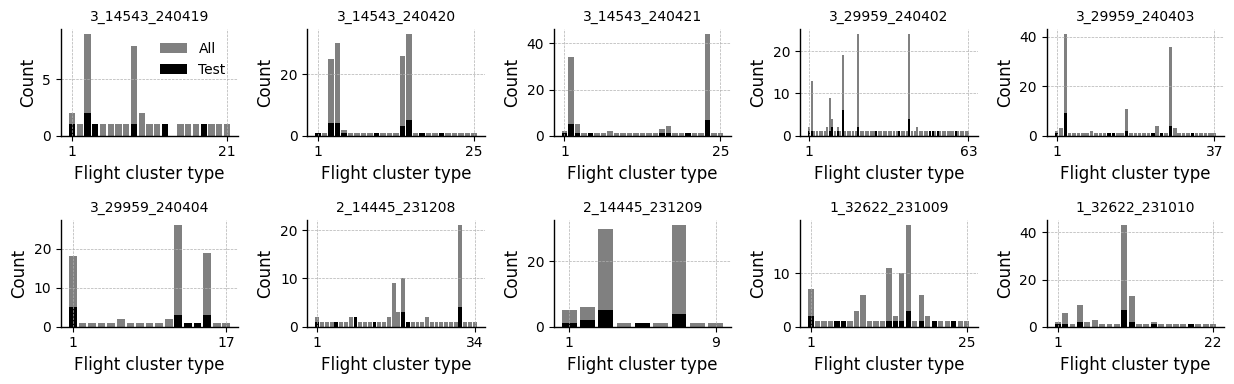

In [7]:
# summarize the flight cluster type distribution
session_names = list(dataloaders['test'].keys())
ncols = 5
nrows = len(session_names) // ncols
fig, axes = plt.subplots(nrows=nrows, ncols=ncols,figsize=(ncols*2.5,nrows*2))
for ii in range(nrows):
    for jj in range(ncols):
        session_name = list(dataloaders['test'].keys()) [ii * ncols + jj]
        flight_type_train = dataloaders['train'][session_name].dataset.flight_type_index.detach().cpu().numpy()
        flight_type_valid = dataloaders['valid'][session_name].dataset.flight_type_index.detach().cpu().numpy()
        flight_type_test = dataloaders['test'][session_name].dataset.flight_type_index.detach().cpu().numpy()
        flight_type = np.concatenate((flight_type_train, flight_type_valid, flight_type_test))
        unique_vals, counts = np.unique(flight_type, return_counts=True)
        unique_vals_test, counts_test = np.unique(flight_type_test, return_counts=True)
        axes[ii,jj].bar(unique_vals, counts, color='gray', label='All')
        axes[ii,jj].bar(unique_vals_test, counts_test, color='k', label='Test')
        axes[ii,jj].set_xticks([1, unique_vals.max()])
        axes[ii,jj].set_xlabel("Flight cluster type")
        axes[ii,jj].set_ylabel("Count")
        axes[ii,jj].set_title(f'{session_name[8:]}', fontsize=10)
axes[0,0].legend(loc='best',frameon=False)
plt.tight_layout()

# Transformer model

In [8]:
model_config = dict(
    input_dim = behavior_dim,
    output_dim_dict=unit_num_dict, 
    # place
    use_place_as_input=False, # add spatial basis
    spatial_centers_sigma_dict=meta_info_dict['spatial_centers_sigma'],
    latent_dim_place = 32,
    # trajectory
    use_trajectory_as_input=True,
    latent_dim = 32, # 256
    ff_dim = 32, # 256
    num_heads = 4, # 4
    num_layers = 1, # 1
    dropout_prob = 0.3, # 0.7
    #
    # use_low_rank = True, # low rank matrix multiplication
    # use_low_rank_readout = True, # low rank for readouts
    # low_rank_r = 4, # 4
    final_activation=ELU1(), # nn.Identity(),
)
bat_former = Bat_Transformer(**model_config)

bat_former

Bat_Transformer(
  (embed_traj): Linear(in_features=3, out_features=32, bias=True)
  (embed_traj_dropout): Dropout(p=0.1, inplace=False)
  (layers): ModuleList(
    (0): TransformerEncoderRoPE(
      (attention): MultiheadAttentionRoPE(
        (W_q): Linear(in_features=32, out_features=32, bias=True)
        (W_k): Linear(in_features=32, out_features=32, bias=True)
        (W_v): Linear(in_features=32, out_features=32, bias=True)
        (W_o): Linear(in_features=32, out_features=32, bias=True)
      )
      (ff): Sequential(
        (0): Linear(in_features=32, out_features=32, bias=True)
        (1): GELU(approximate='none')
        (2): Linear(in_features=32, out_features=32, bias=True)
      )
      (dropout): Dropout(p=0.3, inplace=False)
      (norm1): LayerNorm((32,), eps=1e-05, elementwise_affine=True)
      (norm2): LayerNorm((32,), eps=1e-05, elementwise_affine=True)
    )
  )
  (readouts): ModuleDict(
    (Dataset_3_14543_240419): Sequential(
      (0): Linear(in_features=32

# Training

In [11]:
# # Hyperparameter tuning for weight_decay using validation set
# from copy import deepcopy

# weight_decay_candidates = [0, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1]

# best_wd_transformer = None
# best_val_score_transformer = -np.inf
# best_weights_transformer = None
# wd_results_transformer = []

# for wd in weight_decay_candidates:
#     print(f'Testing weight_decay={wd}')
    
#     # Create model, warm-start from previous best if available
#     bat_former_tune = Bat_Transformer(**model_config)
#     if best_weights_transformer is not None:
#         bat_former_tune.load_state_dict(deepcopy(best_weights_transformer))
    
#     # Train with this weight_decay
#     tune_config = dict(
#         model=bat_former_tune,
#         dataloaders=dataloaders,
#         device=device,
#         is_causal=False,
#         is_bigbird=False,
#         attention_window_size=9,
#         num_global=2,
#         n_epochs=1000,
#         lr=0.01,
#         weight_decay=wd,
#         loss_fn=nn.PoissonNLLLoss(log_input=False),
#         valid_fn=poisson_fde_population,
#         valid_stat='median',
#         early_stopping_patience=100,
#         save_model=False,
#     )
#     val_score, weights, val_scores = bat_former_trainer(**tune_config)
#     wd_results_transformer.append({'weight_decay': wd, 'val_score': val_score})
#     print(f'  Final val score (median FDE, filtered): {val_score:.4f}')
    
#     if val_score > best_val_score_transformer:
#         best_val_score_transformer = val_score
#         best_wd_transformer = wd
#         best_weights_transformer = deepcopy(weights)

# print(f'\nBest weight_decay: {best_wd_transformer} with val score: {best_val_score_transformer:.4f}')

# # Plot results
# fig, ax = plt.subplots(figsize=(6, 4))
# wds = [r['weight_decay'] for r in wd_results_transformer]
# scores = [r['val_score'] for r in wd_results_transformer]
# ax.semilogx([w if w > 0 else 1e-6 for w in wds], scores, 'o-')
# ax.axvline(best_wd_transformer if best_wd_transformer > 0 else 1e-6, color='r', linestyle='--', label=f'Best: {best_wd_transformer}')
# ax.set_xlabel('Weight Decay')
# ax.set_ylabel('Validation FDE (median, filtered)')
# ax.set_title('Transformer Weight Decay Tuning')
# ax.legend()
# plt.show()

Training:  62%|██████▏   | 622/1000 [02:09<01:18,  4.80it/s]

Early stopping at epoch 623 (no improvement for 100 epochs)
Final model trained with weight_decay=0.001, best val score: 0.0722


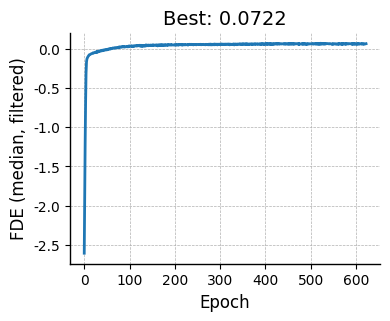

In [23]:
# Set best_wd_transformer here if skipping tuning loop
best_wd_transformer = 0.001
model_name=f'./out/bat_former_seed_{seed}_wd_{best_wd_transformer}.pth'

# Train final Transformer with best weight_decay
bat_former = Bat_Transformer(**model_config)  # Fresh model

trainer_config = dict(
    model=bat_former,
    dataloaders=dataloaders,
    device=device,
    is_causal=False,
    is_bigbird=False,
    attention_window_size=9,
    num_global=2,
    n_epochs=1000,
    lr=0.01,
    weight_decay=best_wd_transformer,
    loss_fn=nn.PoissonNLLLoss(log_input=False),
    valid_fn=poisson_fde_population,
    valid_stat='median',
    early_stopping_patience=100,
    save_model=True,
    model_name=model_name,
)

best_acc, best_weights, acc_vals = bat_former_trainer(**trainer_config)
print(f'Final model trained with weight_decay={best_wd_transformer}, best val score: {best_acc:.4f}')

fig, axes = plt.subplots(nrows=1, ncols=1, figsize=(4, 3))
axes.plot(acc_vals)
axes.set_title(f"Best: {best_acc:.4f}")
axes.set_xlabel("Epoch")
axes.set_ylabel("FDE (median, filtered)")
plt.show()

# Evaluation

In [24]:
def evaluate_model(model, dataloaders, valid_fn, device, flight_filter=None, meta_info_dict=None):
    """
    Evaluate model on test data.
    
    Args:
        model: trained model in eval mode
        dataloaders: dict with 'test' key
        valid_fn: function(y_true, y_pred) -> scores array
        device: torch device
        flight_filter: None (all), 'ood', or 'indomain'
        meta_info_dict: required if flight_filter is not None
    
    Returns:
        dict mapping session_name -> scores array
    """
    results = {}
    model.eval()
    
    for session_name, session_data in dataloaders['test'].items():
        # Get flight type filter if needed
        if flight_filter == 'ood':
            target_types = np.array(meta_info_dict['flight_type_test_ood'][session_name], dtype=int)
            if target_types.size == 0:
                results[session_name] = np.array([])
                continue
        elif flight_filter == 'indomain':
            target_types = np.array(meta_info_dict['flight_type_test_indomain'][session_name], dtype=int)
        else:
            target_types = None
        
        y_val_list, y_pred_list = [], []
        for batch in session_data:
            X_val = batch.behavior.to(device)
            y_val = batch.spike.to(device)
            mask_val = batch.mask.to(device)
            
            # Filter by flight type if needed
            if target_types is not None:
                batch_mask = np.isin(batch.flight_type_index.numpy(), target_types)
                if not batch_mask.any():
                    continue
                X_val = X_val[batch_mask]
                y_val = y_val[batch_mask]
                mask_val = mask_val[batch_mask]
            
            y_pred = model(session_name, X_val, mask_val)
            y_val_list.append(y_val[mask_val == 1.0].detach().cpu().numpy())
            y_pred_list.append(y_pred[mask_val == 1.0].detach().cpu().numpy())
        
        if y_val_list:
            y_val_np = np.vstack(y_val_list)
            y_pred_np = np.vstack(y_pred_list)
            results[session_name] = valid_fn(y_val_np, y_pred_np)
        else:
            results[session_name] = np.array([])
    
    return results

In [177]:
# Load trained model
bat_former.load_state_dict(torch.load(model_name, map_location=device))
bat_former = bat_former.to(device)

# Define metrics and filters to evaluate
metrics = {
    'corr': lambda y_true, y_pred: corr(y_true, y_pred, axis=0),
    'fde': lambda y_true, y_pred: poisson_fde_population(y_true, y_pred),
}
flight_filters = [None, 'ood', 'indomain']  # None = all flights

# Evaluate all combinations
transformer_results = {}
for metric_name, valid_fn in metrics.items():
    for flight_filter in flight_filters:
        key = f"{metric_name}_{flight_filter or 'all'}"
        transformer_results[key] = evaluate_model(
            bat_former, dataloaders, valid_fn, device,
            flight_filter=flight_filter, meta_info_dict=meta_info_dict
        )
        # Print summary
        all_scores = np.hstack([v for v in transformer_results[key].values() if len(v) > 0])
        stat = np.nanmedian if 'fde' in key else np.nanmean
        print(f"{key}: {stat(all_scores):.4f}")

corr_all: 0.2537
corr_ood: 0.1417
corr_indomain: 0.2721
fde_all: 0.0714
fde_ood: -0.1112
fde_indomain: 0.0912


## Corr. vs. FDE

In [26]:
# Corr. vs. FDE
if False:
    ncols = 5
    nrows = len(list(dataloaders['test'].keys())) // ncols
    fig, axes = plt.subplots(nrows=nrows, ncols=ncols,figsize=(ncols*2.5,nrows*2))
    for ii in range(nrows):
        for jj in range(ncols):
            session_name = list(dataloaders['test'].keys()) [ii * ncols + jj]
            axes[ii,jj].scatter(corr_dict[session_name], fde_dict[session_name], color='k', s=1)
            axes[ii,jj].set_ylim(-1.0, 1)
            axes[ii,jj].set_xlabel('Corr.')
            axes[ii,jj].set_ylabel('FDE')
            axes[ii,jj].set_title(f'{session_name[8:]}', fontsize=10)
    plt.tight_layout()

## Rate map

session_target: Dataset_3_29959_240403


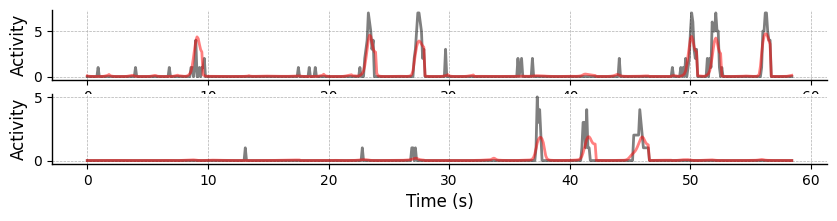

In [27]:
session_target = list(dataloaders['test'].keys())[4]
print(f'session_target: {session_target}')
bat_former.load_state_dict(torch.load(model_name, map_location=device))
# bat_former.load_state_dict(best_weights)
bat_former = bat_former.to(device)
bat_former.eval()
for session_name, session_data in dataloaders['test'].items():
    # print(session_name, session_data)
    if session_name == session_target:
        X_val_np_list = []
        y_val_np_list = []
        y_pred_np_list = []
        for batch_id, batch in enumerate(session_data):
            X_val = batch[0].to(device)
            y_val = batch[1].to(device)
            mask_val = batch[2].to(device)
            y_pred = bat_former(
                session_name, 
                X_val, 
                mask_val, 
                is_causal=trainer_config['is_causal'], 
                is_bigbird=trainer_config['is_bigbird'], 
                attention_window_size=trainer_config['attention_window_size'],
                num_global=trainer_config['num_global'],
            )
            X_val_np = X_val.detach()[mask_val == 1.0].cpu().numpy()
            y_val_np = y_val.detach()[mask_val == 1.0].cpu().numpy() 
            y_pred_np = y_pred.detach()[mask_val == 1.0].cpu().numpy()
            # print(f'X_val_np.shape: {X_val_np.shape}, y_val_np.shape: {y_val_np.shape}')
            X_val_np_list.append(X_val_np)
            y_val_np_list.append(y_val_np)
            y_pred_np_list.append(y_pred_np)
        X_val_np = np.vstack(X_val_np_list)
        y_val_np = np.vstack(y_val_np_list)
        y_pred_np = np.vstack(y_pred_np_list)
        # print(f'X_val_np.shape: {X_val_np.shape}, y_val_np.shape: {y_val_np.shape}')
        temp_scores = valid_fn(y_val_np, y_pred_np) # an array of scores for spiking units in one batch data within one session of data

ccs = np.copy(temp_scores)

temps = np.arange(-1, -3, -1).tolist() 
num = y_val_np.shape[0]
nrows = len(temps)
fig, ax = plt.subplots(nrows=nrows, ncols=1, figsize=(10, nrows))
for ii in range(nrows):
    temp = np.argsort(ccs)[temps[ii]]
    ax[ii].plot(np.arange(num) * data_config['bin_width'], y_val_np[:num, temp], color='k', alpha=0.5)
    ax[ii].plot(np.arange(num) * data_config['bin_width'], y_pred_np[:num,temp], color='red', alpha=0.5)
    ax[ii].set_xlabel("Time (s)") 
    ax[ii].set_ylabel("Activity")

In [28]:
print(f'session_target: {session_target}')
bat_former.load_state_dict(torch.load(model_name, map_location=device))
# bat_former.load_state_dict(best_weights)
bat_former = bat_former.to(device)
bat_former.eval()
for session_name, session_data in dataloaders['test'].items():
    # print(session_name, session_data)
    if session_name == session_target:
        X_val_np_list = []
        y_val_np_list = []
        y_pred_np_list = []
        mask_val_list = []
        flight_path_index_list = []
        flight_type_index_list = []
        for batch_id, batch in enumerate(session_data):
            X_val = batch.behavior.to(device)
            y_val = batch.spike.to(device)
            mask_val = batch.mask.to(device)
            y_pred = bat_former(
                session_name, 
                X_val, 
                mask_val, 
                is_causal=trainer_config['is_causal'], 
                is_bigbird=trainer_config['is_bigbird'], 
                attention_window_size=trainer_config['attention_window_size'],
                num_global=trainer_config['num_global'],
            )
            X_val_np = X_val.detach().cpu().numpy()
            y_val_np = y_val.detach().cpu().numpy() 
            y_pred_np = y_pred.detach().cpu().numpy()
            mask_val_np = mask_val.detach().cpu().numpy()
            flight_path_index_np = batch.flight_path_index.detach().cpu().numpy()
            flight_type_index_np = batch.flight_type_index.detach().cpu().numpy()
            #
            X_val_np_list.append(X_val_np)
            y_val_np_list.append(y_val_np)
            y_pred_np_list.append(y_pred_np)
            mask_val_list.append(mask_val_np)
            flight_path_index_list.append(flight_path_index_np)
            flight_type_index_list.append(flight_type_index_np)
X_val_np = np.vstack(X_val_np_list)
y_val_np = np.vstack(y_val_np_list)
y_pred_np = np.vstack(y_pred_np_list)
mask_val = np.vstack(mask_val_list)
flight_path_index = np.hstack(flight_path_index_list) # use hstack for stacking 1D arrays
flight_type_index = np.hstack(flight_type_index_list) # use hstack for stacking 1D arrays
print(f'X_val_np.shape: {X_val_np.shape}, y_val_np.shape: {y_val_np.shape}, y_pred_np.shape: {y_pred_np.shape}, mask_val.shape: {mask_val.shape}')
# X_val_np.shape: (64, 68, 3), y_val_np.shape: (64, 68, 168), y_pred_np.shape: (64, 68, 168), mask_val.shape: (64, 68),... 64 batches, 68 time points, 168 neurons
print(f'flight_path_index.shape: {flight_path_index.shape}, flight_type_index.shape: {flight_type_index.shape}') # flight_path_index.shape: (64,), flight_type_index.shape: (64,)
print(f'flight_path_index: {flight_path_index}')
print(f'flight_type_index: {flight_type_index}')

session_target: Dataset_3_29959_240403
X_val_np.shape: (21, 73, 3), y_val_np.shape: (21, 73, 191), y_pred_np.shape: (21, 73, 191), mask_val.shape: (21, 73)
flight_path_index.shape: (21,), flight_type_index.shape: (21,)
flight_path_index: [ 38.  34.  15.  36. 103.   0.  56.  11.  42.  84.  63.  10.  33. 125.
  68.  76.  81. 102.  93.  57.   5.]
flight_type_index: [ 3.  3.  3.  3. 27.  1. 13.  3.  3. 27. 17.  3.  3. 32. 17. 23. 25. 27.
 27. 14.  3.]


session_target: Dataset_3_29959_240403


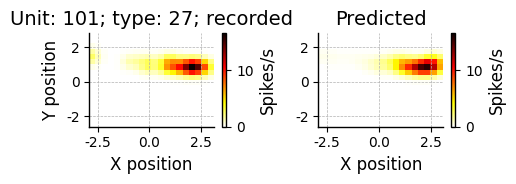

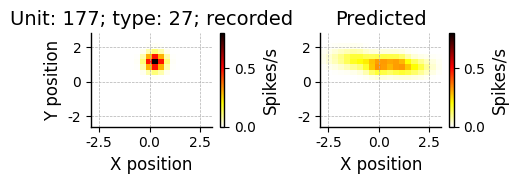

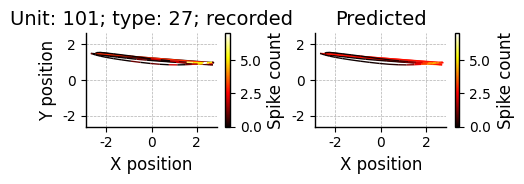

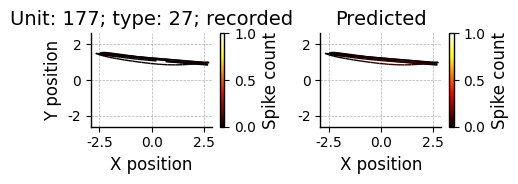

In [29]:
print(f'session_target: {session_target}')
target_type = 27
target_ind = np.where(flight_type_index == target_type)[0]
#
target_X_val = X_val_np[target_ind, :, :]
target_y_val = y_val_np[target_ind, :, :]
target_y_pred = y_pred_np[target_ind, :, :]
target_mask_val = mask_val[target_ind, ]
#
target_X_val = target_X_val[target_mask_val == 1.0]
target_y_val = target_y_val[target_mask_val == 1.0]
target_y_pred = target_y_pred[target_mask_val == 1.0]
# print(f'target_X_val.shape: {target_X_val.shape}, target_y_val.shape: {target_y_val.shape}, target_y_pred.shape: {target_y_pred.shape}')
# target_X_val.shape: (1512, 3), target_y_val.shape: (1512, 168), target_y_pred.shape: (1512, 168) # 168 neurons
loc_xx = target_X_val[:, 0] * meta_info_dict['behavior_std'][session_target][0, 0, 0] + meta_info_dict['behavior_mean'][session_target][0, 0, 0]
loc_yy = target_X_val[:, 1] * meta_info_dict['behavior_std'][session_target][0, 0, 1] + meta_info_dict['behavior_mean'][session_target][0, 0, 1]
loc_xx_lim = meta_info_dict['r_lim'][session_target][0, :]
loc_yy_lim = meta_info_dict['r_lim'][session_target][1, :]
loc_bin_width = 0.3 # the bin width for the location space
dt = np.copy(data_config['bin_width'])  # time interval for each data point (in seconds)
#
units = np.argsort(ccs)[-2:][::-1]
for unit in units:
    spike_count_val = target_y_val[:, unit]
    spike_count_pred = target_y_pred[:, unit]
    plot_2d_rate_map(
        unit=unit,
        target_type=target_type,
        loc_xx=loc_xx,
        loc_yy=loc_yy,
        spike_count_val=spike_count_val,
        spike_count_pred=spike_count_pred,
        loc_xx_lim=loc_xx_lim,
        loc_yy_lim=loc_yy_lim,
        loc_bin_width=loc_bin_width,
        dt=dt,
    )
for unit in units:
    spike_count_val = target_y_val[:, unit]
    spike_count_pred = target_y_pred[:, unit]
    plot_2d_trajectory_response(
        unit=unit,
        target_type=target_type,
        loc_xx=loc_xx,
        loc_yy=loc_yy,
        spike_count_val=spike_count_val,
        spike_count_pred=spike_count_pred,
        loc_xx_lim=loc_xx_lim,
        loc_yy_lim=loc_yy_lim,
    )

# Attention matrix

session_target: Dataset_3_29959_240403


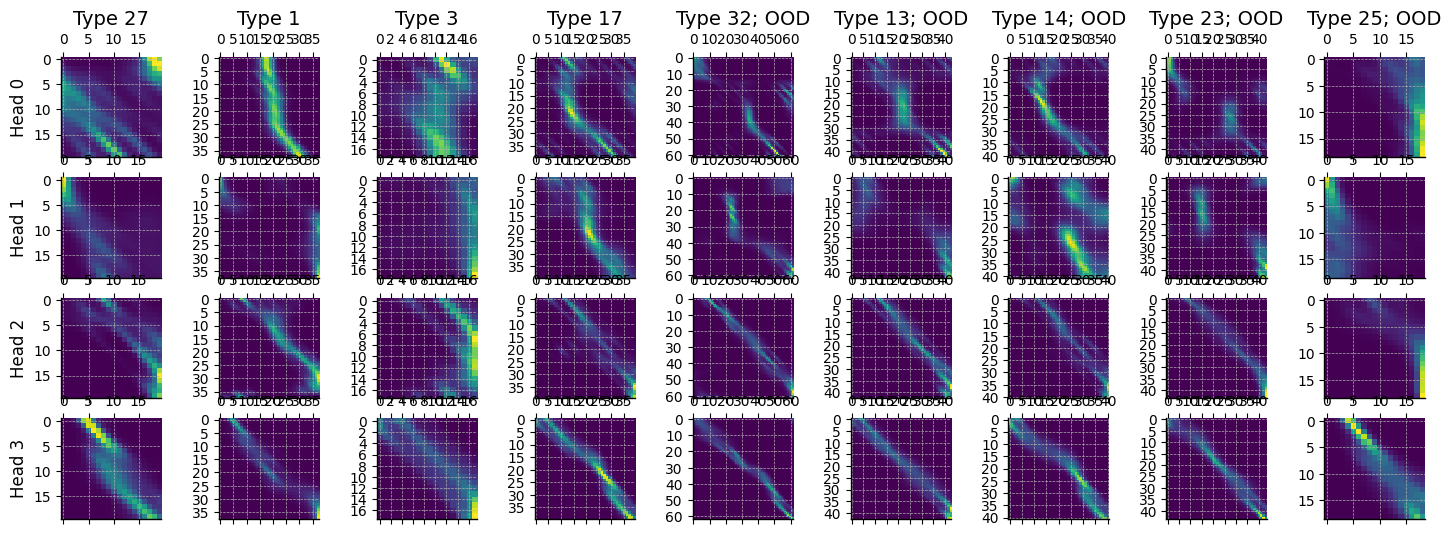

In [30]:
# Show attention weights for each flight cluster type within test data
session_target = list(dataloaders['test'].keys())[4]
print(f'session_target: {session_target}')
bat_former.load_state_dict(torch.load(model_name, map_location=device))
# bat_former.load_state_dict(best_weights)
bat_former = bat_former.to(device)
bat_former.eval()
for session_name, session_data in dataloaders['test'].items():
    # print(session_name, session_data)
    if session_name == session_target:
        # we have only one batch of test data
        for batch_id, batch in enumerate(session_data):
            X_val = batch[0].to(device)
            y_val = batch[1].to(device)
            mask_val = batch[2].to(device)
            flight_type_index = batch.flight_type_index.detach().cpu().numpy()
            y_pred, attn_weights_list = bat_former(
                session_name, 
                X_val, 
                mask_val, 
                is_causal=trainer_config['is_causal'], 
                is_bigbird=trainer_config['is_bigbird'], 
                attention_window_size=trainer_config['attention_window_size'],
                num_global=trainer_config['num_global'],
                return_attn_weights=True,
            )
            X_val_np = X_val.detach().cpu().numpy()
            mask_val_np = mask_val.detach().cpu().numpy()
attn_weights_list = [attn_weights.detach().cpu().numpy() for attn_weights in attn_weights_list]
target_types_indomain = np.array(meta_info_dict['flight_type_test_indomain'][session_target], dtype=int)
target_types_ood = np.array(meta_info_dict['flight_type_test_ood'][session_target], dtype=int)
target_types = np.concatenate((target_types_indomain, target_types_ood))

if True:
    nrows = attn_weights_list[0].shape[1]
    ncols = len(target_types_indomain) + len(target_types_ood)
    np.random.seed(1000)
    fig, ax = plt.subplots(nrows=nrows, ncols=ncols, figsize=(ncols*2, nrows*1.5))
    for ii in range(nrows):
        for jj in range(ncols):
            batch_ind, head_ind = np.where(flight_type_index == target_types[jj])[0][0], ii
            # only show the unmask elements (not padding ones)
            unmask_T = int(np.sum(mask_val.detach().cpu().numpy(), axis=1)[batch_ind])
            # plt.imshow(attn_weights_list[0][10,1])
            ax[ii,jj].matshow(attn_weights_list[0][batch_ind, head_ind][:unmask_T, :unmask_T])
        ax[ii,0].set_ylabel(f'Head {ii}')
    for jj in range(ncols):
        ax[0,jj].set_title(f'Type {target_types[jj]}' if target_types[jj] in target_types_indomain else f'Type {target_types[jj]}; OOD')

session_target: Dataset_3_29959_240403


Text(0, 0.5, 'Importance')

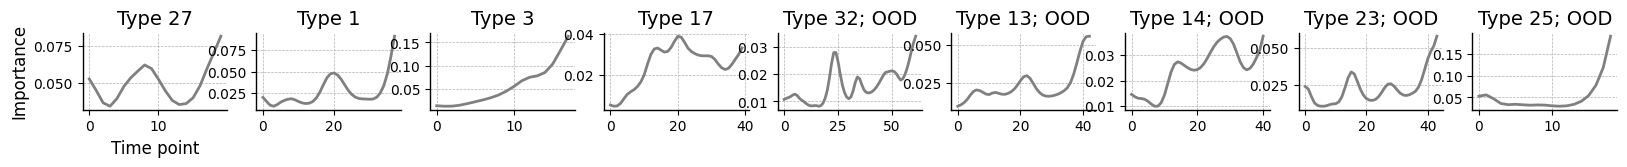

In [31]:
# For each attention matrix, we aggregate weights over the query axis and compute an importance score per time point
# that reflects its overall influence on the model's internal representation (i.e., how strongly the model attends to each position).
# we normalize the score by the length of the query (each flight path) and n_head
print(f'session_target: {session_target}')
ncols = len(target_types) 
nheads = attn_weights_list[0].shape[1] 
fig, ax = plt.subplots(nrows=1, ncols=ncols, figsize=(ncols*2.2, 1.0))
for ii in range(ncols): # for each flight cluster type
    inds = np.where(flight_type_index==target_types[ii])[0]
    temps = []
    for jj in range(1): # for each flight path: for jj in range(counts[ii]) # for now, we only use one flight path # TODO
        for kk in range(nheads): # for each attention head
            batch_ind, head_ind = inds[jj], kk
            # only show the unmask elements (not padding ones)
            unmask_T = int(np.sum(mask_val.detach().cpu().numpy(), axis=1)[batch_ind])
            temps.append(np.sum(attn_weights_list[0][batch_ind, head_ind][:unmask_T, :unmask_T], axis=0)/(unmask_T*nheads)) # sum across query
    temp = np.sum(np.array(temps), axis=0) # sum across heads and flight paths (belong to the same type)
    # ax[ii].bar(np.arange(len(temp)), temp, color='gray')
    ax[ii].plot(np.arange(len(temp)), temp, color='gray')
    ax[ii].set_title(f'Type {target_types[ii]}' if target_types[ii] in target_types_indomain else f'Type {target_types[ii]}; OOD')
ax[0].set_xlabel('Time point')
ax[0].set_ylabel('Importance')

session_target: Dataset_3_29959_240403


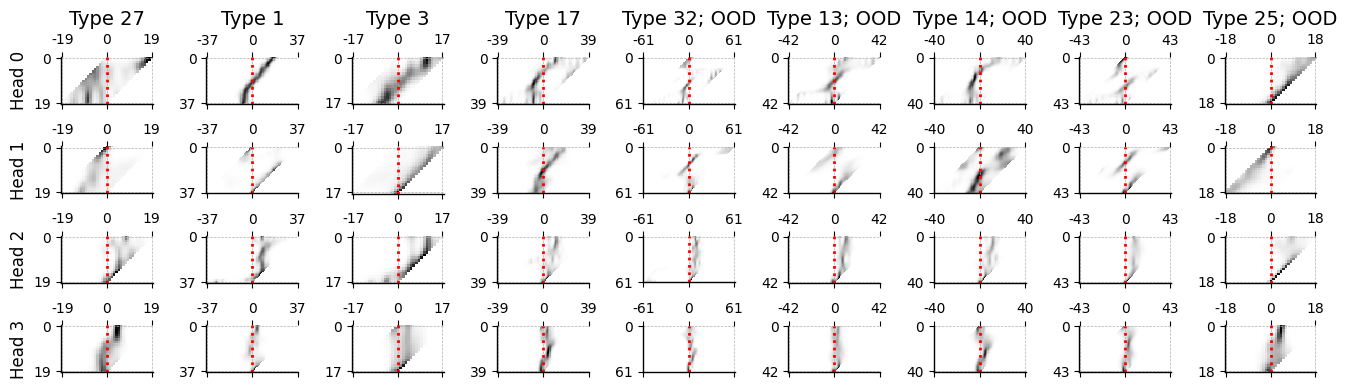

In [32]:
# For each time point, we reindex the attention matrix by a specific temporal offset relative to the query position, 
# producing a time-lag importance profile that quantifies how strongly each position attends to the past, present, and future. 
# This transformation enables direct comparison of temporal dependencies across all positions in the sequence.
from digitalbat.utility.utils import compute_shift_attention
print(f'session_target: {session_target}')
nrows = attn_weights_list[0].shape[1]
ncols = len(target_types)
np.random.seed(1000)
# batch_inds = np.where(flight_type_index==unique_flight_types[temp_ind])[0] # np.random.randint(0, attn_weights_list[0].shape[0], size = ncols)
fig, ax = plt.subplots(nrows=nrows, ncols=ncols, figsize=(ncols*1.5, nrows*1))
for ii in range(nrows):
    for jj in range(ncols):
        batch_ind, head_ind = np.where(flight_type_index==target_types[jj])[0][0], ii
        # only show the unmask elements (not padding ones)
        unmask_T = int(np.sum(mask_val.detach().cpu().numpy(), axis=1)[batch_ind])
        # plt.imshow(attn_weights_list[0][10,1])
        shift_attn = compute_shift_attention(attn_weights_list[0][batch_ind, head_ind][:unmask_T, :unmask_T])
        # ax[ii,jj].imshow(np.log10(shift_attn+1e-7), cmap='gray_r')
        ax[ii,jj].matshow(shift_attn, cmap='gray_r')
        ax[ii,jj].axvline(unmask_T-1, color='red', linestyle=':')
        ax[ii,jj].set_yticks([0, shift_attn.shape[0]-1])
        ax[ii,jj].set_xticks([0, unmask_T-1, shift_attn.shape[1]-1])
        ax[ii,jj].set_xticklabels([-(unmask_T-1), 0, unmask_T-1])
    ax[ii,0].set_ylabel(f'Head {ii}')
for jj in range(ncols):
    ax[0,jj].set_title(f'Type {target_types[jj]}' if target_types[jj] in target_types_indomain else f'Type {target_types[jj]}; OOD')
plt.tight_layout()

session_target: Dataset_3_29959_240403


Text(0, 0.5, 'Importance')

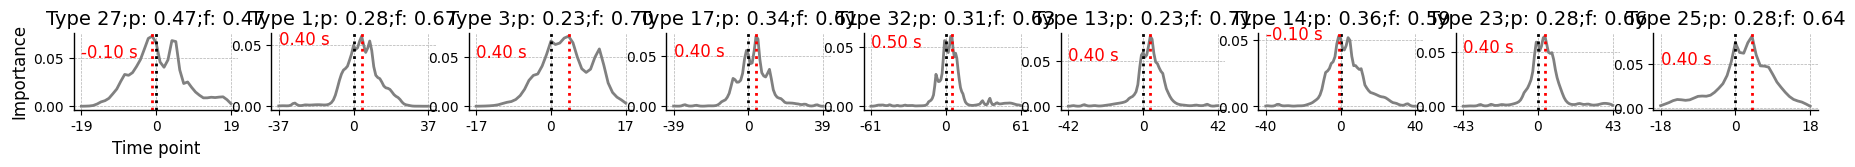

In [33]:
# For each shift attention matrix, we aggregate weights over the query axis and compute an importance score per time point
print(f'session_target: {session_target}')
ncols = len(target_types) 
nheads = attn_weights_list[0].shape[1] 
fig, ax = plt.subplots(nrows=1, ncols=ncols, figsize=(ncols*2.5, 1.0))
for ii in range(ncols): # for each flight cluster type
    inds = np.where(flight_type_index==target_types[ii])[0]
    temps = []
    for jj in range(1): # for each flight path: for jj in range(counts[ii]) # for now, we only use one flight path # TODO
        for kk in range(nheads): # for each attention head
            batch_ind, head_ind = inds[jj], kk
            # only show the unmask elements (not padding ones)
            unmask_T = int(np.sum(mask_val.detach().cpu().numpy(), axis=1)[batch_ind])
            shift_attn = compute_shift_attention(attn_weights_list[0][batch_ind, head_ind][:unmask_T, :unmask_T])
            temps.append(np.sum(shift_attn, axis=0)/(unmask_T*nheads)) # sum across query
    temp = np.sum(np.array(temps), axis=0) # sum across heads and flight paths (belong to the same type)
    # ax[ii].bar(np.arange(len(temp)), temp, color='gray')
    ax[ii].plot(np.arange(len(temp)), temp, color='gray')
    ax[ii].axvline(unmask_T-1, color='k', linestyle=':')
    ax[ii].axvline(np.argmax(temp), color='red', linestyle=':')
    ax[ii].text(0, 0.05, f"{(np.argmax(temp)-(unmask_T-1)) * data_config['bin_width']:.2f} s", color='red')
    ax[ii].set_xticks([0, unmask_T-1, shift_attn.shape[1]-1])
    ax[ii].set_xticklabels([-(unmask_T-1), 0, unmask_T-1])
    ax[ii].set_title(f'Type {target_types[ii]};p: {np.sum(temp[:unmask_T-1]):.2f};f: {np.sum(temp[unmask_T:]):.2f}')
ax[0].set_xlabel('Time point')
ax[0].set_ylabel('Importance')

session_target: Dataset_3_29959_240403


Text(0, 0.5, 'Query time')

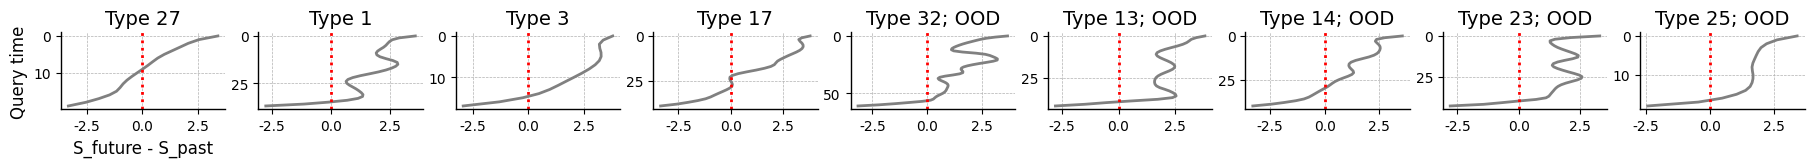

In [34]:
# For each (shift) attention, for each query time position, we aggregate scores over the key axis separately for the past and the future
# and then we subtract the past from the future. At the start of a flight, of course, it only attends to the future. The question is that
# when it starts to attend more to the past.
print(f'session_target: {session_target}')
ncols = len(target_types) 
nheads = attn_weights_list[0].shape[1] 
fig, ax = plt.subplots(nrows=1, ncols=ncols, figsize=(ncols*2.5, 1.0))
for ii in range(ncols): # for each flight cluster type
    inds = np.where(flight_type_index==target_types[ii])[0]
    temps = []
    for jj in range(1): # for each flight path: for jj in range(counts[ii]) # for now, we only use one flight path # TODO
        for kk in range(nheads): # for each attention head
            batch_ind, head_ind = inds[jj], kk
            # only show the unmask elements (not padding ones)
            unmask_T = int(np.sum(mask_val.detach().cpu().numpy(), axis=1)[batch_ind])
            shift_attn = compute_shift_attention(attn_weights_list[0][batch_ind, head_ind][:unmask_T, :unmask_T])
            temps.append(np.sum(shift_attn[:,unmask_T:],axis=1) - np.sum(shift_attn[:,:unmask_T-1], axis=1)) # (future - past) for each query time position 
    temp = np.sum(np.array(temps), axis=0) # sum across heads and flight paths (belong to the same type)
    # ax[ii].barh(np.arange(len(temp)), temp, color='gray')
    ax[ii].plot(temp, np.arange(len(temp)), color='gray')
    ax[ii].invert_yaxis()
    ax[ii].axvline(0.0, color='red', linestyle=':')
    ax[ii].set_title(f'Type {target_types[ii]}' if target_types[ii] in target_types_indomain else f'Type {target_types[ii]}; OOD')
ax[0].set_xlabel('S_future - S_past')
ax[0].set_ylabel('Query time')

session_target: Dataset_3_29959_240403


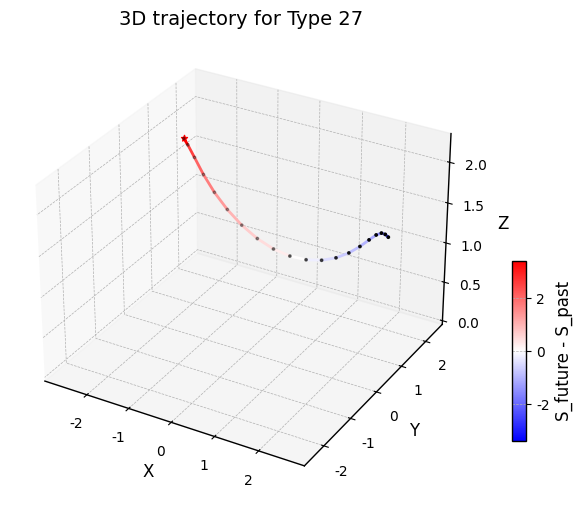

In [35]:
# Plot the 3d trajectory of one flight path (from each flight cluster type), colorized by S_future - S_past 
print(f'session_target: {session_target}')
nheads = attn_weights_list[0].shape[1] # attn_weights_list[0].shape: (64, 4, 68, 68) (batch_size, nheads, T, T)
for ii in range(1): # for ii in range(len(target_types)); for ii in range(1)
    inds = np.where(flight_type_index==target_types[ii])[0]
    for jj in range(1): # for flight paths belong to that type: for jj in range(len(inds)) # for now, we only use one flight path # TODO
        batch_ind = inds[jj]
        temps = []
        for kk in range(nheads): # for each attention head
            # only show the unmask elements (not padding ones)
            unmask_T = int(np.sum(mask_val_np, axis=1)[batch_ind]) # mask_val_np.shape: (64, 68) (batch_size, T)
            shift_attn = compute_shift_attention(attn_weights_list[0][batch_ind, kk][:unmask_T, :unmask_T])
            temps.append(np.sum(shift_attn[:,unmask_T:],axis=1) - np.sum(shift_attn[:,:unmask_T-1], axis=1)) # (future - past) for each query time position 
        s_fut_past = np.sum(np.array(temps), axis=0) # sum across heads 
    
        plot_config = dict(
            # X_val_np.shape: (64, 68, 3) (batch_size, T, 3)
            trajectory_3d = X_val_np[batch_ind][mask_val_np[batch_ind]==1.0,:] * meta_info_dict['behavior_std'][session_target][0,:,:] + meta_info_dict['behavior_mean'][session_target][0,:,:], 
            loc_lim = meta_info_dict['r_lim'][session_target], 
            flight_cluster_type = int(flight_type_index[batch_ind]),
            time_bin_width = data_config['bin_width'],
            visualize_array = s_fut_past, 
            cmap = 'bwr', 
            set_zero_as_medium = True,
            cax_ylabel = 'S_future - S_past', # colorbar ylabel
        )
        plot_3d_trajectory(
            **plot_config
        )

# Saliency

session_target: Dataset_3_29959_240403; target_neuron_index: 20; target_flight_type: 14


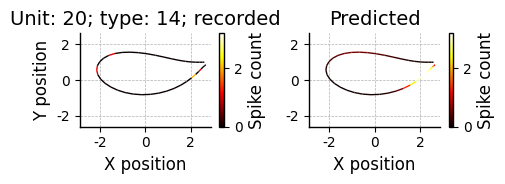

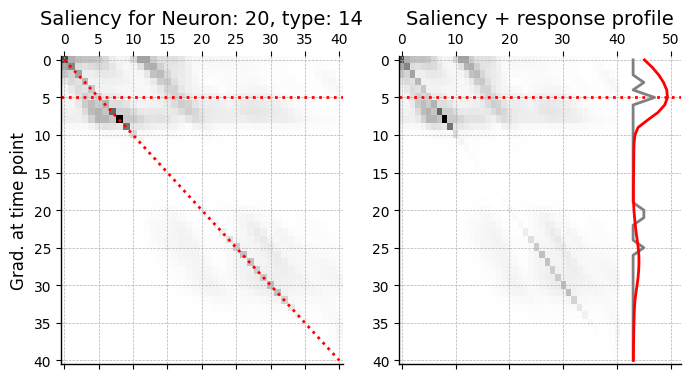

In [36]:
session_target = list(dataloaders['test'].keys())[4] # [4]
target_neuron_index = 20 # 139 # 177
# get the input (flight path) and its mask
target_flight_type = 14 # 32, 23
print(f'session_target: {session_target}; target_neuron_index: {target_neuron_index}; target_flight_type: {target_flight_type}')
for session_name, session_data in dataloaders['test'].items():
    # print(session_name, session_data)
    if session_name == session_target:
        # we have only one batch of test data
        for batch_id, batch in enumerate(session_data):
            X_val = batch[0].to(device)
            y_val = batch[1].to(device)
            mask_val = batch[2].to(device)
            flight_type_index = batch.flight_type_index.detach().cpu().numpy()
            target_flight_index = int(np.where(flight_type_index == target_flight_type)[0][0])
X_val = X_val[target_flight_index][None, :, :]
y_val = y_val[target_flight_index][None, :, :]
mask_val = mask_val[target_flight_index][None, :]
# model
bat_former.load_state_dict(torch.load(model_name, map_location=device))
# bat_former.load_state_dict(best_weights)
bat_former = bat_former.to(device)
bat_former.eval()
# compute gradient
grad_bat_former = Gradient_Bat_Transformer(
    model = bat_former,
    session_name = session_target, 
    X_val = X_val, # flight path; (torch.Size([1, num_of_time_points, 3]),
    y_val = y_val, # (torch.Size([1, num_of_time_points, num_of_neurons])
    mask_val = mask_val, # mask for the path; torch.Size([1, num_of_time_points]))
    target_neuron_index = target_neuron_index,
    trainer_config = trainer_config,
    device = device,
)
grad_bat_former.compute_feature_importance()

target_X_val = grad_bat_former.flight_path
loc_xx = target_X_val[:, 0] * meta_info_dict['behavior_std'][session_target][0, 0, 0] + meta_info_dict['behavior_mean'][session_target][0, 0, 0]
loc_yy = target_X_val[:, 1] * meta_info_dict['behavior_std'][session_target][0, 0, 1] + meta_info_dict['behavior_mean'][session_target][0, 0, 1]
loc_xx_lim = meta_info_dict['r_lim'][session_target][0, :]
loc_yy_lim = meta_info_dict['r_lim'][session_target][1, :]
spike_count_val = grad_bat_former.response_val
spike_count_pred = grad_bat_former.response_pred
plot_2d_trajectory_response(
    unit=target_neuron_index,
    target_type=target_flight_type,
    loc_xx=loc_xx,
    loc_yy=loc_yy,
    spike_count_val=spike_count_val,
    spike_count_pred=spike_count_pred,
    loc_xx_lim=loc_xx_lim,
    loc_yy_lim=loc_yy_lim,
)

fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(8,4))
axs[0].matshow(np.linalg.norm(np.array(grad_bat_former.gradient_list), axis=2), cmap='gray_r', aspect='auto')
axs[0].axhline(y = np.argmax(grad_bat_former.response_pred), color='red', linestyle=':')
# plt.plot((grad_bat_former.unmask_T, grad_bat_former.unmask_T), (0, grad_bat_former.unmask_T), color='red', linestyle=':')
axs[0].plot((0, grad_bat_former.unmask_T-1), (0, grad_bat_former.unmask_T-1), color='red', linestyle=':')
axs[0].set_title(f'Saliency for Neuron: {target_neuron_index}, type: {target_flight_type}')
axs[0].set_ylabel('Grad. at time point')

axs[1].matshow(np.linalg.norm(np.array(grad_bat_former.gradient_list), axis=2), cmap='gray_r', aspect='auto')
axs[1].axhline(y = np.argmax(grad_bat_former.response_pred), color='red', linestyle=':')
# axs[1].plot((0, grad_bat_former.unmask_T-1), (0, grad_bat_former.unmask_T-1), color='red', linestyle=':')
axs[1].set_title(f'Saliency + response profile')
axs[1].plot(grad_bat_former.response_val * 2 + grad_bat_former.unmask_T + 2, np.arange(grad_bat_former.unmask_T), color='gray')
axs[1].plot(grad_bat_former.response_pred * 2 + grad_bat_former.unmask_T + 2, np.arange(grad_bat_former.unmask_T), color='r')

Saliency + response profile: session_target: Dataset_3_29959_240403, target_flight_type: 14


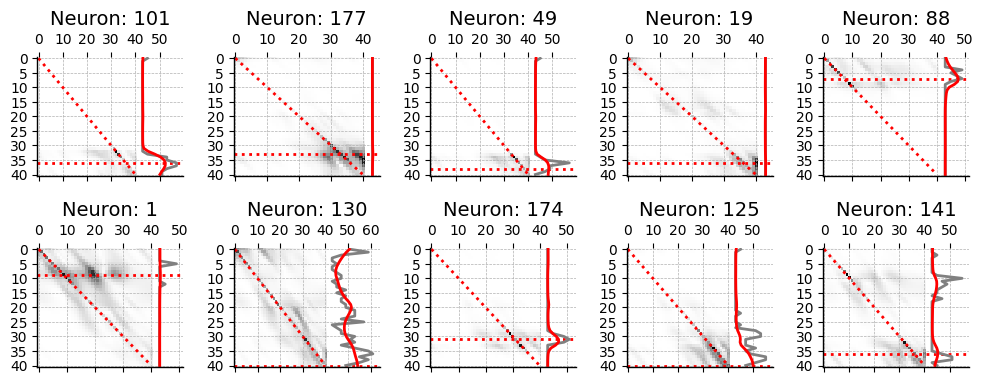

In [37]:
# Show saliency and reponse profiles for multiple neurons during the same flight path
target_flight_type = 14 # 25 # 32, 23
print(f'Saliency + response profile: session_target: {session_target}, target_flight_type: {target_flight_type}')
target_neuron_indices = np.argsort(transformer_results['corr_ood'][session_target])[::-1][:10]
ncols = 5
nrows = int(len(target_neuron_indices)/ncols)
fig, axs = plt.subplots(nrows=nrows, ncols=ncols, figsize=(ncols*2, nrows*2))
for ii in range(nrows):
    for jj in range(ncols):
        target_neuron_index = target_neuron_indices[ii*ncols+jj]

        # get the input (flight path) and its mask
        for session_name, session_data in dataloaders['test'].items():
            # print(session_name, session_data)
            if session_name == session_target:
                # we have only one batch of test data
                for batch_id, batch in enumerate(session_data):
                    X_val = batch[0].to(device)
                    y_val = batch[1].to(device)
                    mask_val = batch[2].to(device)
                    flight_type_index = batch.flight_type_index.detach().cpu().numpy()
                    target_flight_index = int(np.where(flight_type_index == target_flight_type)[0][0])
        X_val = X_val[target_flight_index][None, :, :]
        y_val = y_val[target_flight_index][None, :, :]
        mask_val = mask_val[target_flight_index][None, :]
        # model
        bat_former.load_state_dict(torch.load(model_name, map_location=device))
        # bat_former.load_state_dict(best_weights)
        bat_former = bat_former.to(device)
        bat_former.eval()
        # compute gradient
        grad_bat_former = Gradient_Bat_Transformer(
            model = bat_former,
            session_name = session_target, 
            X_val = X_val, # flight path; (torch.Size([1, num_of_time_points, 3]),
            y_val = y_val, # (torch.Size([1, num_of_time_points, num_of_neurons])
            mask_val = mask_val, # mask for the path; torch.Size([1, num_of_time_points]))
            target_neuron_index = target_neuron_index,
            trainer_config = trainer_config,
            device = device,
        )
        grad_bat_former.compute_feature_importance()
        
        axs[ii,jj].matshow(np.linalg.norm(np.array(grad_bat_former.gradient_list), axis=2), cmap='gray_r', aspect='auto')
        axs[ii,jj].axhline(y = np.argmax(grad_bat_former.response_pred), color='red', linestyle=':')
        axs[ii,jj].plot((0, grad_bat_former.unmask_T-1), (0, grad_bat_former.unmask_T-1), color='red', linestyle=':')
        axs[ii,jj].set_title(f'Neuron: {target_neuron_index}')
        axs[ii,jj].plot(grad_bat_former.response_val * 2 + grad_bat_former.unmask_T + 2, np.arange(grad_bat_former.unmask_T), color='gray')
        axs[ii,jj].plot(grad_bat_former.response_pred * 2 + grad_bat_former.unmask_T + 2, np.arange(grad_bat_former.unmask_T), color='r')
plt.tight_layout()

# Hierarchical clustering and orthogonality test

## Analysis

In [309]:
inds_sessions = {} # a dictionary of neuronal indices for each session
pType_sessions = {}  # pType arrays from meta_info_dict, filtered to selected units
readout_weight_sessions = [] # readout weights for selected units from all sessions
for session_target in list(dataloaders['test'].keys()):
    bat_former.load_state_dict(torch.load(model_name, map_location=device))
    bat_former = bat_former.to(device)
    bat_former.eval()
    readout_weights = bat_former.readouts[session_target][0].weight.detach().cpu().numpy()
    n_neurons = readout_weights.shape[0]
    inds = np.arange(n_neurons)
    inds_sessions[session_target] = inds
    pType_sessions[session_target] = np.asarray(meta_info_dict['pType'][session_target])
    readout_weight_sessions.append(readout_weights)
readout_weight_sessions = np.vstack(readout_weight_sessions)
print(f'readout_weight_sessions.shape: {readout_weight_sessions.shape}')

inds_sessions_df = pd.concat(
    [
        pd.DataFrame({
            "session_neuron_idx": inds,
            "session_name": session
        })
        for session, inds in inds_sessions.items()
    ],
    ignore_index=True
)
inds_sessions_df["global_neuron_idx"] = range(len(inds_sessions_df))

# Attach pType (putative cell type)
inds_sessions_df['pType'] = np.concatenate(
    [pType_sessions[s] for s in inds_sessions.keys()]
)

# Attach per-neuron metrics from transformer_results
for key in transformer_results:
    inds_sessions_df[key] = np.concatenate(
        [transformer_results[key][s] for s in inds_sessions.keys()]
    )

# Store readout weights (unit-normed) directly in the dataframe
norms = np.linalg.norm(readout_weight_sessions, axis=1, keepdims=True)
readout_normed = readout_weight_sessions / norms
inds_sessions_df['readout_weight'] = list(readout_normed)
inds_sessions_df.loc[inds_sessions_df['pType'].apply(lambda x: isinstance(x, np.ndarray)), 'pType'] = 'filtered'
ct_df = inds_sessions_df[inds_sessions_df['pType'].isin(['pPYR', 'pINT'])].copy()

readout_weight_sessions.shape: (1767, 32)


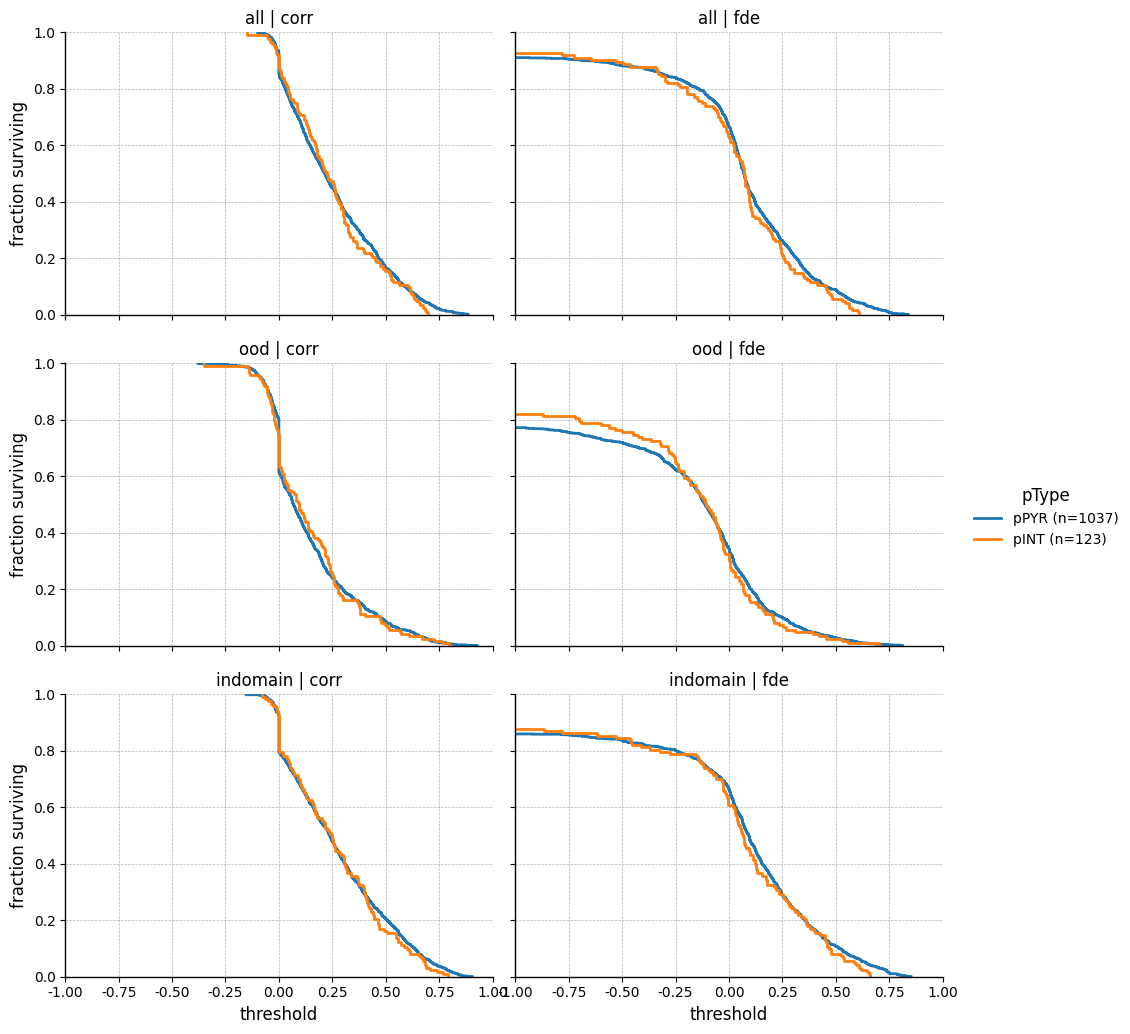

In [311]:
# Fraction of neurons per pType surviving increasing metric thresholds
metric_cols = [c for c in ct_df.columns if c.startswith(('corr_', 'fde_'))]
long_df = ct_df.melt(id_vars='pType', value_vars=metric_cols,
                     var_name='key', value_name='value')
long_df[['metric', 'domain']] = long_df['key'].str.split('_', n=1, expand=True)

# Label pTypes with counts
counts = ct_df['pType'].value_counts()
long_df['pType'] = long_df['pType'].map(lambda p: f'{p} (n={counts[p]})')

# Compute survival fraction via rank
long_df['fraction'] = long_df.groupby(['key', 'pType'])['value'].rank(pct=True)

g = sns.FacetGrid(long_df, row='domain', col='metric',
                  hue='pType', sharey=True, sharex='col',
                  height=3.5, aspect=1.4)
g.map_dataframe(sns.ecdfplot, x='value', complementary=True)
g.add_legend(title='pType')
g.set_axis_labels('threshold', 'fraction surviving')
g.set_titles(row_template='{row_name}', col_template='{col_name}')
g.tight_layout()
for ax in g.axes.flat:
    ax.set_xlim(left=-1, right=1)


In [312]:
from scipy.spatial.distance import pdist, squareform
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.cluster.hierarchy import fcluster

clu_df = inds_sessions_df.loc[inds_sessions_df['corr_all'] > 0.2].copy()
X = np.copy(clu_df['readout_weight'].tolist()) # shape (363, readout_dim)
X = X / np.linalg.norm(X, axis=1, keepdims=True)
# cosine distance = 1 - cosine similarity
dist_condensed = pdist(X, metric="cosine") # shape (363 * 362 / 2,)
dist_matrix = squareform(dist_condensed)  # shape (363, 363)
# Hierarchical clustering
Z = linkage(dist_condensed, method="average")
# The dendrogram returns the leaf order that optimally reflects the hierarchy
dendro = dendrogram(Z, no_plot=True)
order = dendro["leaves"]  # list of reordered neuron indices
# Reorder the distance matrix
dist_matrix_reordered = dist_matrix[np.ix_(order, order)]

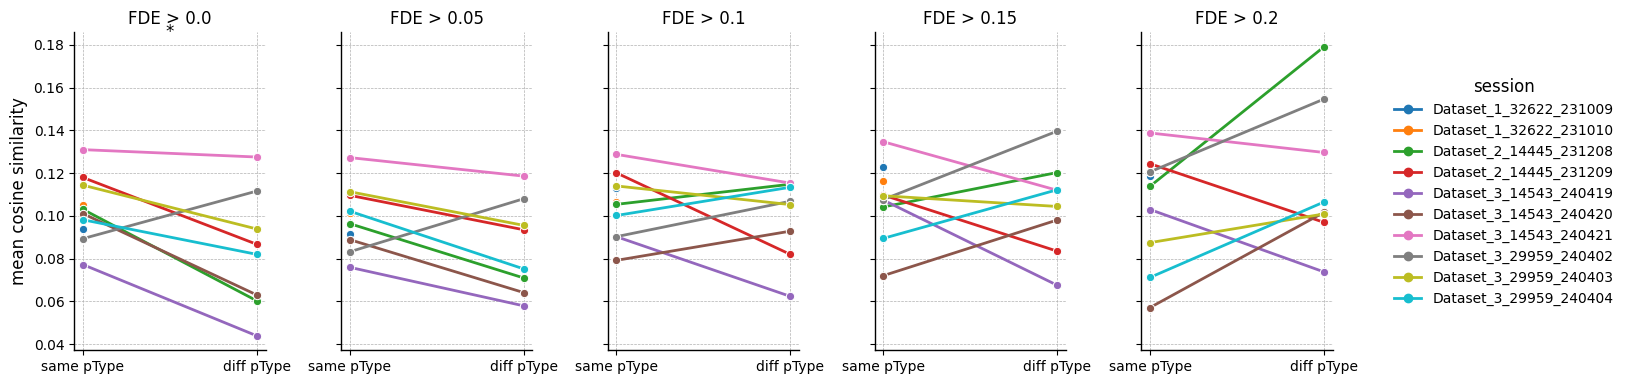

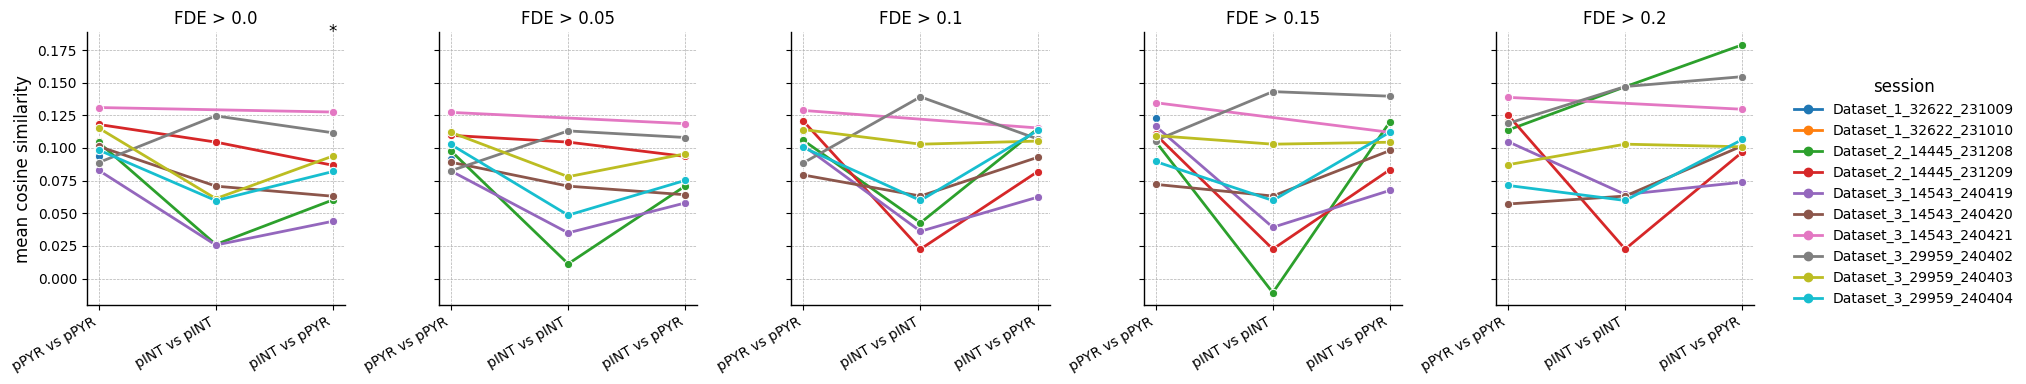

In [313]:
# Pairwise cosine similarity of readout weights, per session and FDE threshold
fde_thresholds = [0, 0.05, 0.1, 0.15, 0.2]
cos_records = []

for fde_thresh in fde_thresholds:
    sub = ct_df[ct_df['fde_all'] > fde_thresh]
    for session_name, grp in sub.groupby('session_name'):
        if len(grp) < 3:
            continue
        W = np.stack(grp['readout_weight'].values)
        cos_sim = W @ W.T
        N = len(grp)
        iu, ju = np.triu_indices(N, k=1)
        pt = grp['pType'].values.astype(str)
        pt_i, pt_j = pt[iu], pt[ju]
        # Canonical pair labels
        lo = np.where(pt_i <= pt_j, pt_i, pt_j)
        hi = np.where(pt_i <= pt_j, pt_j, pt_i)
        pair_label = np.char.add(np.char.add(lo, ' vs '), hi)
        # Same vs diff
        same = pt_i == pt_j
        if same.any():
            cos_records.append(dict(
                fde_thresh=fde_thresh, session=session_name,
                comparison='same pType',
                mean_cosine_sim=cos_sim[iu[same], ju[same]].mean(),
            ))
        if (~same).any():
            cos_records.append(dict(
                fde_thresh=fde_thresh, session=session_name,
                comparison='diff pType',
                mean_cosine_sim=cos_sim[iu[~same], ju[~same]].mean(),
            ))
        # Per-pair breakdown
        for pair in np.unique(pair_label):
            mask = pair_label == pair
            cos_records.append(dict(
                fde_thresh=fde_thresh, session=session_name,
                comparison=pair,
                mean_cosine_sim=cos_sim[iu[mask], ju[mask]].mean(),
            ))

cos_df = pd.DataFrame(cos_records)

# --- Plot 1: same vs diff pType, paired by session ---
cos_same_diff = cos_df[cos_df['comparison'].isin(['same pType', 'diff pType'])]
g = sns.relplot(
    data=cos_same_diff, x='comparison', y='mean_cosine_sim',
    col='fde_thresh', hue='session', kind='line',
    marker='o', height=4, aspect=0.7,
    facet_kws=dict(sharey=True),
)
# Wilcoxon signed-rank test per threshold
for ax, fde_thresh in zip(g.axes.flat, fde_thresholds):
    pivot = (cos_same_diff[cos_same_diff['fde_thresh'] == fde_thresh]
             .pivot(index='session', columns='comparison', values='mean_cosine_sim')
             .dropna())
    if len(pivot) >= 5:
        _, p = wilcoxon(pivot['same pType'], pivot['diff pType'], alternative='greater')
        plot_stars([p], ax, x=[0.5])
g.set_axis_labels('', 'mean cosine similarity')
g.set_titles('FDE > {col_name}')
g.tight_layout()

# --- Plot 2: per-pair breakdown, paired by session ---
pair_names = ['pINT vs pINT', 'pINT vs pPYR', 'pPYR vs pPYR']
cos_pairs = cos_df[cos_df['comparison'].isin(pair_names)]
g2 = sns.relplot(
    data=cos_pairs, x='comparison', y='mean_cosine_sim',
    col='fde_thresh', hue='session', kind='line',
    marker='o', height=4, aspect=0.9,
    facet_kws=dict(sharey=True),
)
# Wilcoxon tests for each within-type vs across-type pair, per threshold
for ax, fde_thresh in zip(g2.axes.flat, fde_thresholds):
    sub = cos_pairs[cos_pairs['fde_thresh'] == fde_thresh]
    pivot = sub.pivot(index='session', columns='comparison', values='mean_cosine_sim').dropna()
    pvals = []
    for pair in pair_names:
        if pair in pivot.columns and 'pINT vs pPYR' in pivot.columns and len(pivot) >= 5:
            if pair == 'pINT vs pPYR':
                pvals.append(1.0)  # reference category
            else:
                _, p = wilcoxon(pivot[pair], pivot['pINT vs pPYR'], alternative='greater')
                pvals.append(p)
        else:
            pvals.append(1.0)
    plot_stars(pvals, ax, x=range(len(pair_names)))
g2.set_axis_labels('', 'mean cosine similarity')
g2.set_titles('FDE > {col_name}')
for ax in g2.axes.flat:
    ax.tick_params(axis='x', rotation=30)
    for lbl in ax.get_xticklabels():
        lbl.set_ha('right')
g2.tight_layout()


pINT: 123, pPYR: 1037, total: 1160
Nested CV balanced accuracy: 0.576


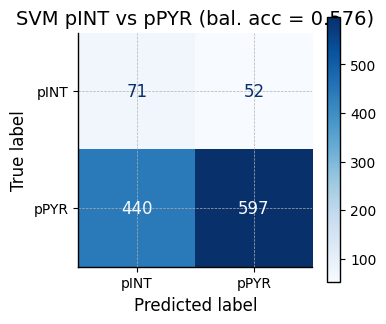

In [314]:
# SVM: predict pINT vs pPYR from readout weights (nested CV, balanced accuracy)
from sklearn.svm import SVC
from sklearn.model_selection import StratifiedKFold, cross_val_predict, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import balanced_accuracy_score, confusion_matrix, ConfusionMatrixDisplay

X_svm = np.stack(ct_df['readout_weight'].values)
y_svm = ct_df['pType'].values.astype(str)
print(f'pINT: {(y_svm=="pINT").sum()}, pPYR: {(y_svm=="pPYR").sum()}, total: {len(y_svm)}')

# Nested cross-validation: outer 10-fold for unbiased accuracy,
# inner 10-fold for C hyper-parameter selection.
outer_cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
inner_cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('svc', SVC(kernel='rbf', class_weight='balanced')),
])
param_grid = {'svc__C': np.logspace(-3, 3, 7)}

# cross_val_predict with GridSearchCV as estimator gives nested CV predictions
nested_clf = GridSearchCV(pipe, param_grid, cv=inner_cv,
                          scoring='balanced_accuracy', n_jobs=-1)
y_pred = cross_val_predict(nested_clf, X_svm, y_svm, cv=outer_cv)

bal_acc = balanced_accuracy_score(y_svm, y_pred)
print(f'Nested CV balanced accuracy: {bal_acc:.3f}')

# Confusion matrix
fig, ax = plt.subplots(figsize=(4, 3.5))
cm = confusion_matrix(y_svm, y_pred, labels=['pINT', 'pPYR'])
disp = ConfusionMatrixDisplay(cm, display_labels=['pINT', 'pPYR'])
disp.plot(ax=ax, cmap='Blues')
ax.set_title(f'SVM pINT vs pPYR (bal. acc = {bal_acc:.3f})')
plt.tight_layout()
plt.show()


In [315]:
# plt.figure(figsize=(7, 7))
# im = plt.imshow(dist_matrix_reordered, origin="lower")
# plt.colorbar(im, label="Cosine distance")
# plt.title("Reordered cosine distance matrix (hierarchical clustering)")
# plt.xlabel("Neuron (reordered)")
# plt.ylabel("Neuron (reordered)")
# plt.tight_layout()

In [316]:
# # plot dendrogram and reordered distance matrix
# fig = plt.figure(figsize=(7, 5))
# # Dendrogram
# ax_dendro = fig.add_axes([0.09, 0.1, 0.2, 0.8])
# dendrogram(
#     Z,
#     orientation="left",
#     # truncate_mode="level",
#     # p=4,                  # show only 4 levels
#     no_labels=True,
#     ax=ax_dendro
# )
# ax_dendro.set_xticks([])
# ax_dendro.set_yticks([])
# # Distance matrix (reordered)
# ax_mat = fig.add_axes([0.3, 0.1, 0.6, 0.8])
# im = ax_mat.matshow(dist_matrix_reordered, aspect="auto", origin="lower")
# ax_mat.set_xticks([])
# ax_mat.set_yticks([])
# # Colorbar
# ax_cb = fig.add_axes([0.92, 0.1, 0.02, 0.8])
# plt.colorbar(im, cax=ax_cb, label="Cosine distance")

In [326]:
# merge_distances = Z[:, 2]
# plt.figure(figsize=(5, 3))
# plt.plot(np.sort(merge_distances)[::-1])
# plt.xlabel("Merge step (largest → smallest)")
# plt.ylabel("Cosine distance")
# plt.title("Hierarchy merge distances")
# plt.tight_layout()

for t in [0.6, 0.7, 0.8, 0.9, 0.95]:
    n = len(np.unique(fcluster(Z, t, criterion="distance")))
    print(f"t={t}: {n} clusters")

t=0.6: 180 clusters
t=0.7: 93 clusters
t=0.8: 38 clusters
t=0.9: 11 clusters
t=0.95: 5 clusters


Text(0.5, 1.0, 'Cluster sizes (t = 0.9)')

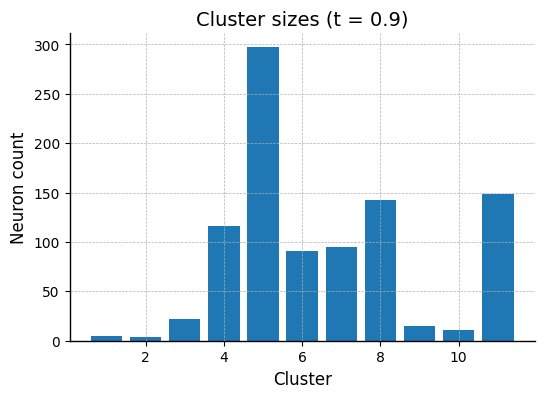

In [332]:
t_use = 0.9
labels = fcluster(Z, t_use, criterion="distance")
unique, counts = np.unique(labels, return_counts=True)

plt.bar(unique, counts)
plt.xlabel("Cluster")
plt.ylabel("Neuron count")
plt.title(f"Cluster sizes (t = {t_use})")

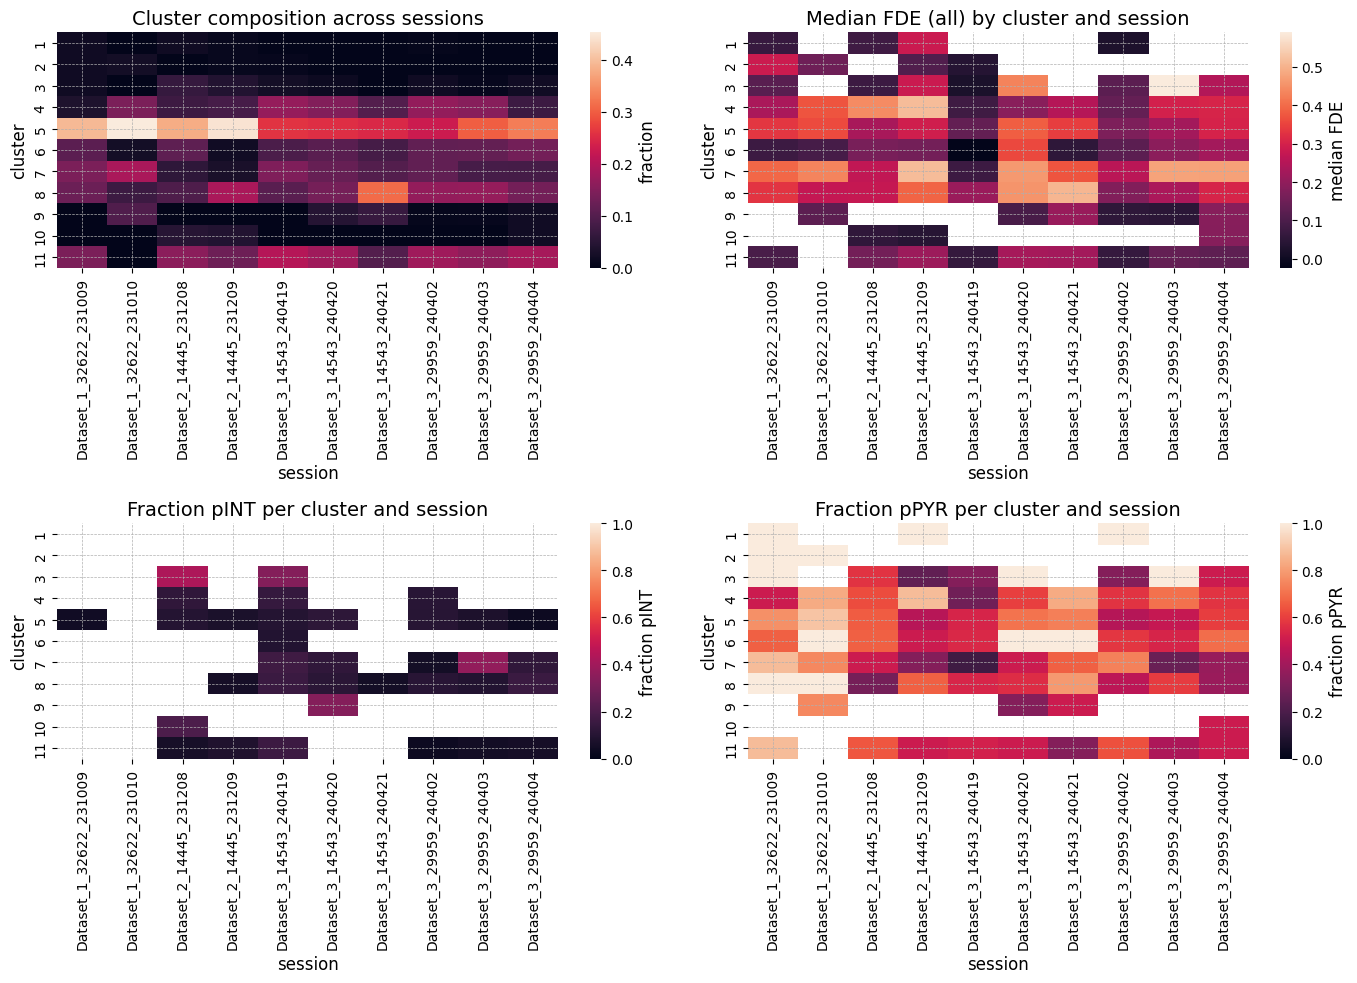

In [333]:
clu_df["cluster"] = labels
ct = pd.crosstab(clu_df["cluster"], clu_df["session_name"], normalize="columns")

# Median FDE per cluster x session
fde_heatmap = (clu_df.groupby(['cluster', 'session_name'])['fde_all']
               .median().unstack('session_name')
               .reindex(index=ct.index, columns=ct.columns))

# Fraction of pINT / pPYR per cluster x session
ptype_fracs = (clu_df.groupby(['cluster', 'session_name'])['pType']
               .value_counts(normalize=True)
               .unstack('pType'))
ptype_names = ['pINT', 'pPYR']
ptype_heatmaps = {}
for pt in ptype_names:
    ptype_heatmaps[pt] = (ptype_fracs[pt].unstack('session_name')
                          .reindex(index=ct.index, columns=ct.columns))

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.heatmap(ct, ax=axes[0, 0], cbar_kws=dict(label='fraction'))
axes[0, 0].set(xlabel='session', ylabel='cluster',
               title='Cluster composition across sessions')

sns.heatmap(fde_heatmap, ax=axes[0, 1], cbar_kws=dict(label='median FDE'))
axes[0, 1].set(xlabel='session', ylabel='cluster',
               title='Median FDE (all) by cluster and session')

for ax, pt in zip(axes[1], ptype_names):
    sns.heatmap(ptype_heatmaps[pt], ax=ax, vmin=0, vmax=1,
                cbar_kws=dict(label=f'fraction {pt}'))
    ax.set(xlabel='session', ylabel='cluster',
           title=f'Fraction {pt} per cluster and session')

plt.tight_layout()


In [334]:
# Reorder neuron metadata
inds_sessions_df_reordered = inds_sessions_df.iloc[order].reset_index(drop=True)
inds_sessions_df_reordered

,session_neuron_idx,session_name,global_neuron_idx,pType,corr_all,corr_ood,corr_indomain,fde_all,fde_ood,fde_indomain,readout_weight
0,226,Dataset_3_29959_240402,741,pPYR,0.415629,0.126538,0.439533,3.474306e-01,-8.290614e-01,4.688743e-01,"[0.0034016236, -0.22591636, -0.12784955, 0.119..."
1,238,Dataset_3_29959_240402,753,unclassified,0.326748,0.138150,0.424261,7.099527e-02,-2.164185e-01,1.888256e-01,"[-0.24475975, 0.219255, -0.027200859, -0.12913..."
2,20,Dataset_3_29959_240403,852,pPYR,0.757111,0.599001,0.778575,5.628508e-01,3.118533e-01,6.173413e-01,"[0.27498817, 0.110837154, 0.030345313, -0.1364..."
3,33,Dataset_3_14543_240420,322,unclassified,0.278543,0.188159,0.350265,2.422273e-02,-6.618309e-02,6.959635e-02,"[0.031514928, -0.26243094, 0.032394346, -0.085..."
4,6,Dataset_3_29959_240403,838,unclassified,0.215071,0.319205,0.189498,2.855933e-02,8.242816e-02,-9.352446e-03,"[0.22990827, -0.1024418, 0.11922785, 0.0788404..."
...,...,...,...,...,...,...,...,...,...,...,...
942,24,Dataset_3_14543_240420,313,pPYR,0.409957,0.136394,0.544696,2.903078e-01,-6.498969e-02,4.948807e-01,"[0.08402552, -0.26741448, -0.15609981, 0.22664..."
943,51,Dataset_3_14543_240419,51,pINT,0.000000,0.000000,0.000000,-5.614840e+32,-5.448012e+32,-1.665411e+31,"[-0.11675157, 0.02597461, -0.16606295, 0.27525..."
944,100,Dataset_3_14543_240419,100,pPYR,0.042048,0.008148,0.256443,-3.313545e-01,-5.782838e-01,3.376968e-01,"[-0.4533818, -0.06150122, -0.0051233806, 0.120..."
945,34,Dataset_3_14543_240419,34,pINT,0.026327,-0.135018,0.252425,-1.657939e-01,-2.410239e-01,-1.312685e-02,"[-0.19818975, 0.13294426, -0.014746608, -0.001..."


Exception ignored in: <function ResourceTracker.__del__ at 0x7b2894272e80>
Traceback (most recent call last):
  File "/home/alowet/miniconda3/envs/gpu/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  File "/home/alowet/miniconda3/envs/gpu/lib/python3.13/multiprocessing/resource_tracker.py", line 91, in _stop
  File "/home/alowet/miniconda3/envs/gpu/lib/python3.13/multiprocessing/resource_tracker.py", line 116, in _stop_locked
ChildProcessError: [Errno 10] No child processes
Exception ignored in: <function ResourceTracker.__del__ at 0x7b9da2d86e80>
Traceback (most recent call last):
  File "/home/alowet/miniconda3/envs/gpu/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  File "/home/alowet/miniconda3/envs/gpu/lib/python3.13/multiprocessing/resource_tracker.py", line 91, in _stop
  File "/home/alowet/miniconda3/envs/gpu/lib/python3.13/multiprocessing/resource_tracker.py", line 116, in _stop_locked
ChildProcessError: [Errno 10] No child 

In [330]:
tester = OrthogonalityPermutationTest(
    X=readout_weight_sessions,
    df=inds_sessions_df,
    session_name=list(dataloaders['test'].keys())[4],
    n_perm=1000,
    random_state=0,
    null_model='shuffle_weights',
)
sig_df = tester.significant_pairs_with_session_indices(alpha=0.05)
sig_df

,session_neuron_idx_1,session_neuron_idx_2,p_value,cosine_distance
0,0,19,0.037962,1.007606
1,0,30,0.040959,0.990867
2,0,79,0.015984,1.003493
3,0,93,0.031968,1.006027
4,0,146,0.007992,1.002305
...,...,...,...,...
499,172,181,0.015984,0.995100
500,173,179,0.002997,0.999914
501,174,182,0.031968,1.008263
502,176,181,0.009990,0.997606


In [324]:
sig_df[sig_df['session_neuron_idx_1'] == 20]

,session_neuron_idx_1,session_neuron_idx_2,p_value,cosine_distance
85,20,62,0.031968,1.007392
86,20,135,0.045954,0.989260
87,20,150,0.014985,1.004108
88,20,164,0.000999,1.000481


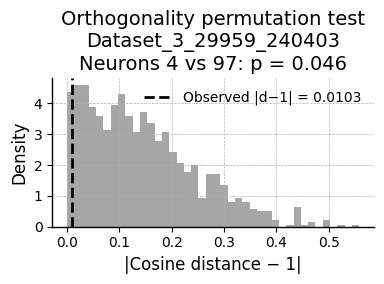

In [325]:
row = sig_df.iloc[21]
tester.plot_null_vs_observed(
    session_neuron_idx_1=row["session_neuron_idx_1"],
    session_neuron_idx_2=row["session_neuron_idx_2"],
)

# GLM models with 3D cosine basis

Two variants: position-only GLM (lag=0) and GLM with time-lagged positions
(lags from -1.0 to +1.0 s in 0.2 s steps).

In [226]:
from digitalbat.models.glm import Bat_GLM


def create_cosine_bumps_torch(x, centers, width):
    """Raised cosine bumps in PyTorch.

    x: (...,) tensor of positions
    centers: (K,) tensor of bump centers
    width: scalar bump width

    returns: (..., K) tensor
    """
    diff = x.unsqueeze(-1) - centers
    return (torch.cos(2 * np.pi * diff / width) * 0.5 + 0.5) * (diff.abs() < width / 2).float()


class GLM_3DCosineBasis(nn.Module):
    """3D tensor-product cosine basis expansion + session-wise linear GLM.

    Uses 3D raised cosine bumps over (x, y, z) z-scored position.
    When `lag_seconds` contains multiple values, the design matrix at each
    time step is the concatenation of spatial bases evaluated at the
    corresponding time-lagged positions (zero-padded at sequence edges).

    Parameters
    ----------
    lag_seconds : list of float
        Time offsets (in seconds) at which to evaluate the spatial basis.
        Default ``[0.0]`` gives the position-only GLM.
    bin_width : float
        Temporal bin width in seconds, used to convert lag_seconds to bins.
    """
    def __init__(
        self,
        output_dim_dict,
        n_bases_per_dim=8,
        pos_range=(-3.0, 3.0),
        width_to_spacing_ratio=4,
        activation='exp',
        lag_seconds=None,
        bin_width=0.1,
    ):
        super().__init__()
        if lag_seconds is None:
            lag_seconds = [0.0]
        self.lag_bins = [int(round(s / bin_width)) for s in lag_seconds]
        n_lags = len(self.lag_bins)

        centers = torch.linspace(pos_range[0], pos_range[1], n_bases_per_dim)
        spacing = (pos_range[1] - pos_range[0]) / (n_bases_per_dim - 1)
        self.register_buffer('centers', centers)
        self.width = width_to_spacing_ratio * spacing
        self.n_bases_per_dim = n_bases_per_dim

        n_spatial = n_bases_per_dim ** 3
        self.glm = Bat_GLM(
            input_dim=n_spatial * n_lags,
            output_dim_dict=output_dim_dict,
            activation=activation,
        )
        if n_lags > 1:
            print(f"GLM: {n_lags} lags x {n_spatial} spatial = "
                  f"{n_spatial * n_lags} features, "
                  f"lag_bins={self.lag_bins}")

    def _spatial_basis(self, xyz):
        """Compute 3D tensor-product cosine basis from (N, T, >=3) positions."""
        centers = self.centers.to(xyz.device)
        b_x = create_cosine_bumps_torch(xyz[..., 0], centers, self.width)
        b_y = create_cosine_bumps_torch(xyz[..., 1], centers, self.width)
        b_z = create_cosine_bumps_torch(xyz[..., 2], centers, self.width)
        bases = (
            b_x.unsqueeze(-1).unsqueeze(-1)
            * b_y.unsqueeze(-2).unsqueeze(-1)
            * b_z.unsqueeze(-2).unsqueeze(-2)
        )
        return bases.flatten(-3)  # (N, T, K^3)
    
    def _make_design(self, x, mask=None):
        # x: (N, T, behavior_dim) — first 3 dims = x, y, z (z-scored by dataloader)
        N, T, _ = x.shape
        spatial = self._spatial_basis(x)  # (N, T, K^3)
        K3 = spatial.shape[-1]

        # Zero out spatial basis at invalid (padded) timesteps BEFORE shifting,
        # so that lags reaching into the padded zone get zeros rather than
        # basis values computed from garbage padding data.
        if mask is not None:
            spatial = spatial * mask.unsqueeze(-1)

        lagged = []
        for lag in self.lag_bins:
            if lag == 0:
                lagged.append(spatial)
            elif lag > 0:
                pad = spatial.new_zeros(N, lag, K3)
                lagged.append(torch.cat([spatial[:, lag:, :], pad], dim=1))
            else:
                pad = spatial.new_zeros(N, -lag, K3)
                lagged.append(torch.cat([pad, spatial[:, :T + lag, :]], dim=1))

        return torch.cat(lagged, dim=-1)  # (N, T, K^3 * n_lags)

    def forward(self, session_name, x, mask=None, **kwargs):
        design = self._make_design(x, mask)
        return self.glm(session_name, design)


glm_common = dict(
    output_dim_dict=unit_num_dict,
    n_bases_per_dim=16,
    pos_range=(-3.0, 3.0),
    width_to_spacing_ratio=4,
    activation='exp',
    bin_width=data_config['bin_width'],
)

glm_variants = {
    'GLM': dict(**glm_common),
    'GLM + lags': dict(**glm_common, lag_seconds=np.arange(-1.0, 1.0 + 1e-9, 0.2).tolist()),
}

glm_models = {}
for name, cfg in glm_variants.items():
    print(f"\n--- {name} ---")
    glm_models[name] = GLM_3DCosineBasis(**cfg)
    print(glm_models[name])


--- GLM ---
GLM_3DCosineBasis(
  (glm): Bat_GLM(
    (readouts): ModuleDict(
      (Dataset_3_14543_240419): Linear(in_features=4096, out_features=289, bias=True)
      (Dataset_3_14543_240420): Linear(in_features=4096, out_features=126, bias=True)
      (Dataset_3_14543_240421): Linear(in_features=4096, out_features=100, bias=True)
      (Dataset_3_29959_240402): Linear(in_features=4096, out_features=317, bias=True)
      (Dataset_3_29959_240403): Linear(in_features=4096, out_features=191, bias=True)
      (Dataset_3_29959_240404): Linear(in_features=4096, out_features=190, bias=True)
      (Dataset_2_14445_231208): Linear(in_features=4096, out_features=237, bias=True)
      (Dataset_2_14445_231209): Linear(in_features=4096, out_features=168, bias=True)
      (Dataset_1_32622_231009): Linear(in_features=4096, out_features=95, bias=True)
      (Dataset_1_32622_231010): Linear(in_features=4096, out_features=54, bias=True)
    )
  )
)

--- GLM + lags ---
GLM: 11 lags x 4096 spatial = 45

### Visualize 3D cosine basis

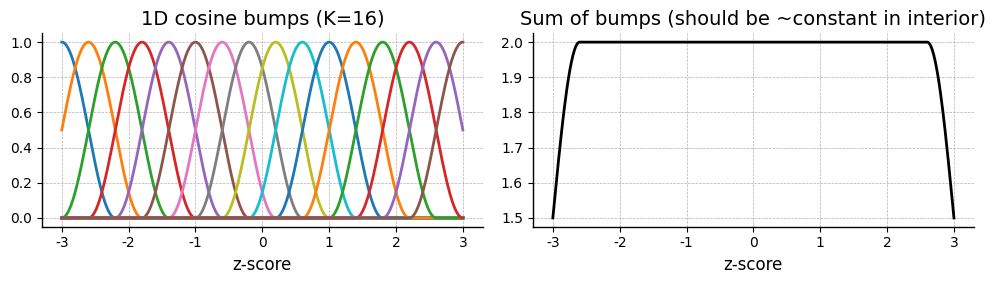

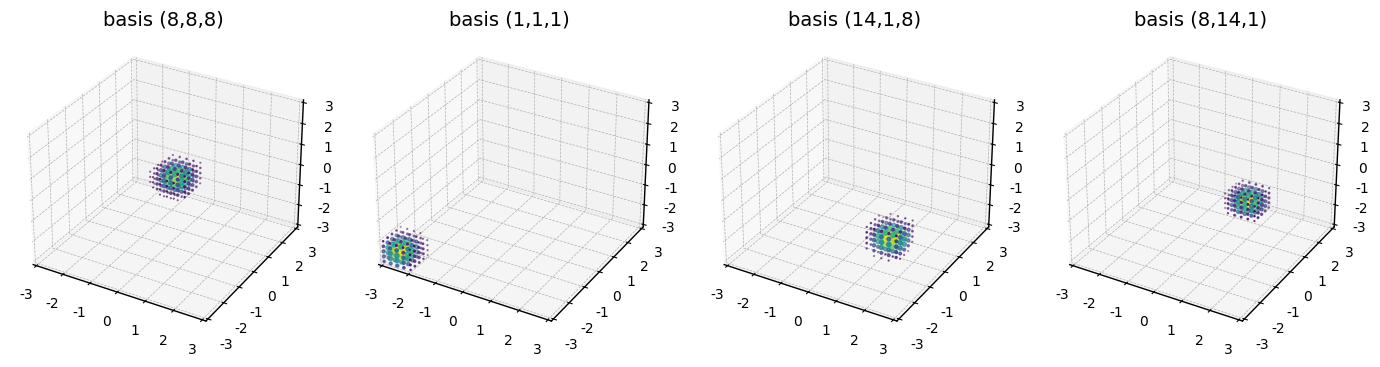

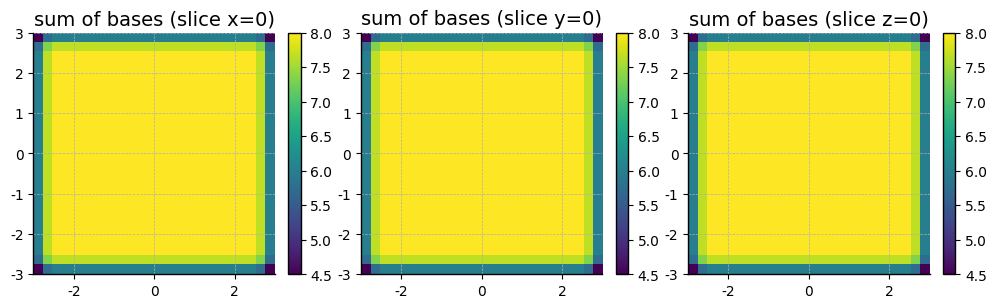

Real positions: shape=(326, 3), x∈[-1.77,1.49], y∈[-2.12,1.50], z∈[-3.58,2.01]


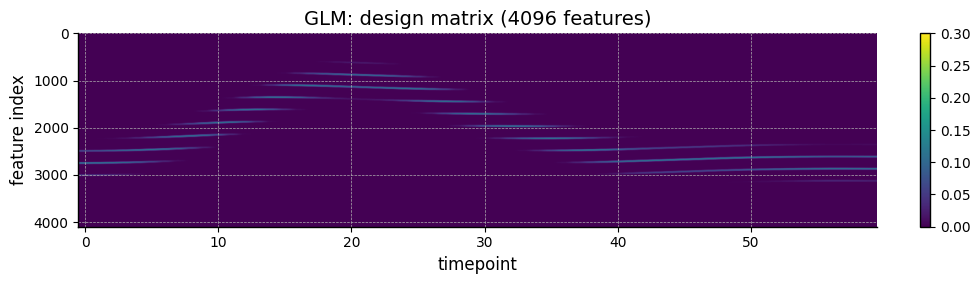

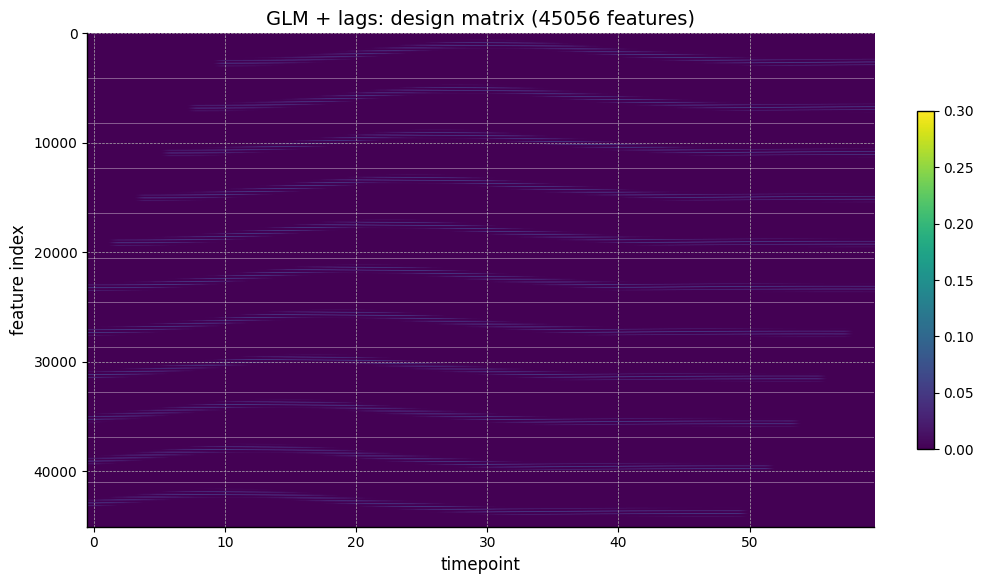

In [227]:
# Sanity check the 3D raised cosine basis used by the GLM.
# 1) 1D cosine bumps along one axis (should tile evenly — sum ≈ constant in interior).
# 2) A few selected 3D basis functions shown as 3D scatter (point size ∝ basis value).
# 3) Sum-of-bases slices (should be ~constant in the interior of the tiled cube).
# 4) Design matrix on real data for both GLM variants.

centers = glm_models['GLM'].centers.cpu().numpy()
width = glm_models['GLM'].width
K = glm_models['GLM'].n_bases_per_dim
lo, hi = float(centers[0]), float(centers[-1])

# --- (1) 1D bumps along one axis ---
xs = torch.linspace(lo, hi, 500)
b1d = create_cosine_bumps_torch(xs, glm_models['GLM'].centers, width).cpu().numpy()
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].plot(xs.numpy(), b1d)
axes[0].set(title=f'1D cosine bumps (K={K})', xlabel='z-score')
axes[1].plot(xs.numpy(), b1d.sum(axis=1), 'k')
axes[1].set(title='Sum of bumps (should be ~constant in interior)', xlabel='z-score')
plt.tight_layout()
plt.show()

# --- (2) Selected 3D basis functions over a 3D grid ---
N_GRID = 25
g = torch.linspace(lo, hi, N_GRID)
X3, Y3, Z3 = torch.meshgrid(g, g, g, indexing='ij')
grid = torch.stack([X3.flatten(), Y3.flatten(), Z3.flatten()], dim=-1)
bx = create_cosine_bumps_torch(grid[:, 0], glm_models['GLM'].centers, width)
by = create_cosine_bumps_torch(grid[:, 1], glm_models['GLM'].centers, width)
bz = create_cosine_bumps_torch(grid[:, 2], glm_models['GLM'].centers, width)
bases_grid = (bx.unsqueeze(-1).unsqueeze(-1) * by.unsqueeze(-2).unsqueeze(-1) * bz.unsqueeze(-2).unsqueeze(-2)).flatten(-3).cpu().numpy()

chosen = [
    (K // 2, K // 2, K // 2),
    (1, 1, 1),
    (K - 2, 1, K // 2),
    (K // 2, K - 2, 1),
]
fig = plt.figure(figsize=(14, 3.5))
for i, (ix, iy, iz) in enumerate(chosen):
    flat_idx = ix * K * K + iy * K + iz
    vals = bases_grid[:, flat_idx]
    keep = vals > 0.01
    ax = fig.add_subplot(1, 4, i + 1, projection='3d')
    ax.scatter(
        grid[keep, 0].cpu(), grid[keep, 1].cpu(), grid[keep, 2].cpu(),
        c=vals[keep], s=20 * vals[keep], cmap='viridis',
    )
    ax.set(title=f'basis ({ix},{iy},{iz})', xlim=(lo, hi), ylim=(lo, hi), zlim=(lo, hi))
plt.tight_layout()
plt.show()

# --- (3) Sum-of-bases slices
total = bases_grid.sum(axis=1).reshape(N_GRID, N_GRID, N_GRID)
mid = N_GRID // 2
fig, axes = plt.subplots(1, 3, figsize=(10, 3))
for ax, sl, name in zip(axes, [total[mid], total[:, mid], total[:, :, mid]], ['x=0', 'y=0', 'z=0']):
    im = ax.imshow(sl, extent=[lo, hi, lo, hi], origin='lower')
    ax.set_title(f'sum of bases (slice {name})')
    plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
plt.show()

# --- (4) Design matrix on real (z-scored) test positions ---
session_name = list(dataloaders['test'].keys())[0]
batch = next(iter(dataloaders['test'][session_name]))
X_real = batch.behavior
mask_real = batch.mask
xyz = X_real[..., :3][mask_real == 1.0]
print(f"Real positions: shape={tuple(xyz.shape)}, "
      f"x∈[{xyz[:,0].min():.2f},{xyz[:,0].max():.2f}], "
      f"y∈[{xyz[:,1].min():.2f},{xyz[:,1].max():.2f}], "
      f"z∈[{xyz[:,2].min():.2f},{xyz[:,2].max():.2f}]")

for i, (name, model) in enumerate(glm_models.items()):
    with torch.no_grad():
        design = model._make_design(X_real, mask_real)

    # Pick one flight, valid timesteps only
    valid = mask_real[0] == 1.0
    design_valid = design[0, valid].cpu().numpy()
    n_features = design_valid.shape[1]

    fig, ax = plt.subplots(figsize=(10, (i+1)*3))
    im = ax.imshow(design_valid.T, aspect='auto', cmap='viridis', vmax=0.3)
    ax.set(xlabel='timepoint', ylabel='feature index',
           title=f'{name}: design matrix ({n_features} features)')
    # Draw lag boundaries if lagged
    n_lags = len(model.lag_bins)
    if n_lags > 1:
        K3 = n_features // n_lags
        for i in range(1, n_lags):
            ax.axhline(i * K3 - 0.5, color='white', lw=0.5, alpha=0.5)
    plt.colorbar(im, ax=ax, fraction=0.02)
    plt.tight_layout()
    plt.show()

## Training


==================== GLM ====================
  Testing weight_decay=0


Training:   8%|▊         | 83/1000 [00:16<03:03,  5.00it/s]


Early stopping at epoch 84 (no improvement for 20 epochs)
    val score: -0.0695
  Testing weight_decay=1e-05


Training:   3%|▎         | 31/1000 [00:06<03:09,  5.12it/s]


Early stopping at epoch 32 (no improvement for 20 epochs)
    val score: -0.0509
  Testing weight_decay=0.0001


...

Early stopping at epoch 21 (no improvement for 20 epochs)
    val score: -0.0533
  Testing weight_decay=0.01


Training:   2%|▏         | 24/1000 [00:03<02:38,  6.16it/s]


Early stopping at epoch 25 (no improvement for 20 epochs)
    val score: -0.0533
  Testing weight_decay=0.1


Training:   2%|▏         | 21/1000 [00:04<03:38,  4.48it/s]

Early stopping at epoch 22 (no improvement for 20 epochs)
    val score: -0.0528
  Best weight_decay: 1e-05 (val=-0.0509)


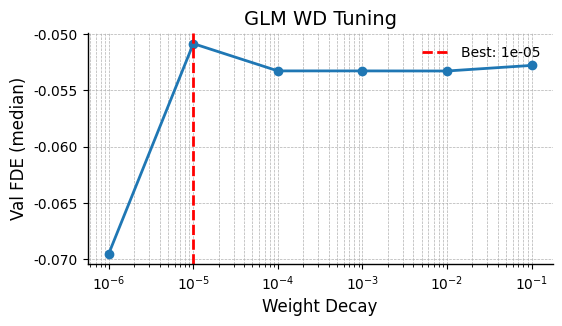


==================== GLM + lags ====================
  Testing weight_decay=0
GLM: 11 lags x 4096 spatial = 45056 features, lag_bins=[-10, -8, -6, -4, -2, 0, 2, 4, 6, 8, 10]


Training:   2%|▎         | 25/1000 [00:06<04:29,  3.61it/s]

Early stopping at epoch 26 (no improvement for 20 epochs)
    val score: -0.0909
  Testing weight_decay=1e-05
GLM: 11 lags x 4096 spatial = 45056 features, lag_bins=[-10, -8, -6, -4, -2, 0, 2, 4, 6, 8, 10]



Training:   2%|▏         | 21/1000 [00:05<04:10,  3.91it/s]

Early stopping at epoch 22 (no improvement for 20 epochs)
    val score: 0.0014
  Testing weight_decay=0.0001
GLM: 11 lags x 4096 spatial = 45056 features, lag_bins=[-10, -8, -6, -4, -2, 0, 2, 4, 6, 8, 10]


...

Early stopping at epoch 22 (no improvement for 20 epochs)
    val score: -0.0043
  Testing weight_decay=0.01
GLM: 11 lags x 4096 spatial = 45056 features, lag_bins=[-10, -8, -6, -4, -2, 0, 2, 4, 6, 8, 10]


Training:   2%|▏         | 21/1000 [00:05<04:20,  3.75it/s]

Early stopping at epoch 22 (no improvement for 20 epochs)
    val score: -0.0043
  Testing weight_decay=0.1
GLM: 11 lags x 4096 spatial = 45056 features, lag_bins=[-10, -8, -6, -4, -2, 0, 2, 4, 6, 8, 10]



Training:   2%|▏         | 21/1000 [00:05<04:09,  3.93it/s]

Early stopping at epoch 22 (no improvement for 20 epochs)
    val score: -0.0041
  Best weight_decay: 1e-05 (val=0.0014)


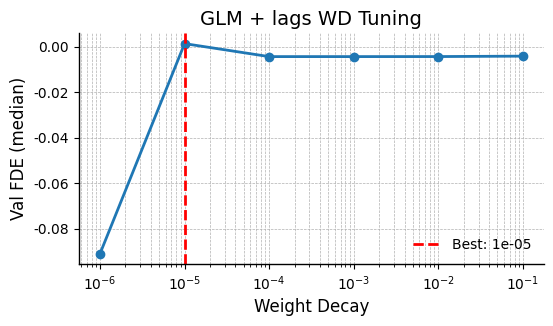

In [ ]:
# # Hyperparameter tuning for weight_decay (both GLM variants)
# from copy import deepcopy

# weight_decay_candidates = [0, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1]

# best_wds = {}
# for name, cfg in glm_variants.items():
#     print(f"\n{'='*20} {name} {'='*20}")
#     best_wd_cur, best_val, best_weights_cur = None, -np.inf, None
#     wd_results_cur = []

#     for wd in weight_decay_candidates:
#         print(f'  Testing weight_decay={wd}')
#         glm_tune = GLM_3DCosineBasis(**cfg)
#         if best_weights_cur is not None:
#             glm_tune.load_state_dict(deepcopy(best_weights_cur))
#         val_score, weights, _ = bat_former_trainer(
#             model=glm_tune, dataloaders=dataloaders, device=device,
#             n_epochs=1000, lr=0.01, weight_decay=wd,
#             loss_fn=nn.PoissonNLLLoss(log_input=False),
#             valid_fn=poisson_fde_population, valid_stat='median',
#             early_stopping_patience=20, save_model=False,
#         )
#         wd_results_cur.append({'weight_decay': wd, 'val_score': val_score})
#         print(f'    val score: {val_score:.4f}')
#         if val_score > best_val:
#             best_val = val_score
#             best_wd_cur = wd
#             best_weights_cur = deepcopy(weights)

#     best_wds[name] = best_wd_cur
#     print(f'  Best weight_decay: {best_wd_cur} (val={best_val:.4f})')

#     fig, ax = plt.subplots(figsize=(6, 3))
#     wds = [r['weight_decay'] for r in wd_results_cur]
#     scores = [r['val_score'] for r in wd_results_cur]
#     ax.semilogx([w if w > 0 else 1e-6 for w in wds], scores, 'o-')
#     ax.axvline(best_wd_cur if best_wd_cur > 0 else 1e-6, color='r', ls='--', label=f'Best: {best_wd_cur}')
#     ax.set(xlabel='Weight Decay', ylabel='Val FDE (median)', title=f'{name} WD Tuning')
#     ax.legend()
#     plt.show()


==================== GLM (wd=1e-05) ====================


Training:   8%|▊         | 82/1000 [00:16<03:02,  5.04it/s]

Early stopping at epoch 83 (no improvement for 20 epochs)
  Best val score: -0.0679


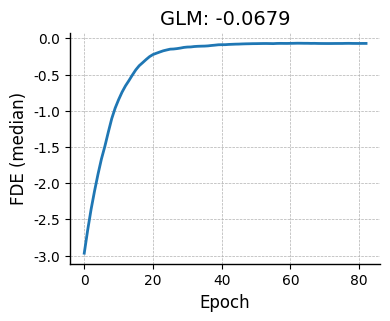


==================== GLM + lags (wd=1e-05) ====================
GLM: 11 lags x 4096 spatial = 45056 features, lag_bins=[-10, -8, -6, -4, -2, 0, 2, 4, 6, 8, 10]


Training:   2%|▎         | 25/1000 [00:06<04:06,  3.95it/s]

Early stopping at epoch 26 (no improvement for 20 epochs)


  Best val score: -0.0900


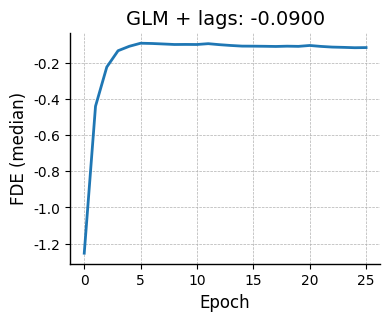

In [235]:
# Set best weight decays here if skipping tuning loop
best_wds = {'GLM': 1e-5, 'GLM + lags': 1e-5}

glm_model_names = {}
for name, cfg in glm_variants.items():
    wd = best_wds[name]
    model_path = f"./out/bat_glm{'_lag' if 'lag' in name else ''}_seed_{seed}_wd_{wd}.pth"
    glm_model_names[name] = model_path

    print(f"\n{'='*20} {name} (wd={wd}) {'='*20}")
    glm_models[name] = GLM_3DCosineBasis(**cfg)

    best_acc, best_weights, acc_vals = bat_former_trainer(
        model=glm_models[name], dataloaders=dataloaders, device=device,
        n_epochs=1000, lr=0.01, weight_decay=wd,
        loss_fn=nn.PoissonNLLLoss(log_input=False),
        valid_fn=poisson_fde_population, valid_stat='median',
        early_stopping_patience=20, save_model=True, model_name=model_path,
    )
    print(f'  Best val score: {best_acc:.4f}')

    fig, ax = plt.subplots(figsize=(4, 3))
    ax.plot(acc_vals)
    ax.set(title=f"{name}: {best_acc:.4f}", xlabel="Epoch", ylabel="FDE (median)")
    plt.show()

## Evaluation

In [236]:
# Evaluate both GLM variants
all_glm_results = {}
for name, cfg in glm_variants.items():
    model_path = glm_model_names[name]
    glm_models[name].load_state_dict(torch.load(model_path, map_location=device))
    glm_models[name] = glm_models[name].to(device)

    results = {}
    for metric_name, valid_fn in metrics.items():
        for flight_filter in flight_filters:
            key = f"{metric_name}_{flight_filter or 'all'}"
            results[key] = evaluate_model(
                glm_models[name], dataloaders, valid_fn, device,
                flight_filter=flight_filter, meta_info_dict=meta_info_dict
            )
            all_scores = np.hstack([v for v in results[key].values() if len(v) > 0])
            stat = np.nanmedian if 'fde' in key else np.nanmean
            print(f"{name} {key}: {stat(all_scores):.4f}")
    all_glm_results[name] = results

# Aliases for backward compatibility with comparison cells
glm_results = all_glm_results['GLM']
glm_lag_results = all_glm_results['GLM + lags']

GLM corr_all: 0.1754
GLM corr_ood: 0.0765
GLM corr_indomain: 0.2157
GLM fde_all: -0.0367
GLM fde_ood: -0.2709
GLM fde_indomain: 0.0020
GLM + lags corr_all: 0.2320
GLM + lags corr_ood: 0.1076
GLM + lags corr_indomain: 0.2705
GLM + lags fde_all: -0.0779
GLM + lags fde_ood: -0.4716
GLM + lags fde_indomain: 0.0004


In [237]:
# Build comparison DataFrame with all subsets (GLM vs GLM+lags vs Transformer)
rows = []
for session_name in transformer_results['corr_all'].keys():
    bat_id = re.search(r'_(\d{5})_', session_name).group(1)
    date_str = session_name[-6:]
    date = datetime.strptime(date_str, '%y%m%d').date()
    n_units = len(transformer_results['corr_all'][session_name])

    model_results = {
        'GLM': glm_results,
        'GLM + lags': glm_lag_results,
        'Transformer': transformer_results,
    }

    for i in range(n_units):
        for subset in ['all', 'ood', 'indomain']:
            corr_key = f'corr_{subset}'
            fde_key = f'fde_{subset}'
            for model_name_str, results_dict in model_results.items():
                rows.append({
                    'session': session_name, 'bat': bat_id, 'date': date, 'unit': i,
                    'model': model_name_str, 'metric': 'Correlation', 'subset': subset,
                    'value': results_dict[corr_key][session_name][i]
                })
                rows.append({
                    'session': session_name, 'bat': bat_id, 'date': date, 'unit': i,
                    'model': model_name_str, 'metric': 'FDE', 'subset': subset,
                    'value': max(results_dict[fde_key][session_name][i], -1)
                })

df = pd.DataFrame(rows)
df

,session,bat,date,unit,model,metric,subset,value
0,Dataset_3_14543_240419,14543,2024-04-19,0,GLM,Correlation,all,-0.013987
1,Dataset_3_14543_240419,14543,2024-04-19,0,GLM,FDE,all,-1.000000
2,Dataset_3_14543_240419,14543,2024-04-19,0,GLM + lags,Correlation,all,-0.011258
3,Dataset_3_14543_240419,14543,2024-04-19,0,GLM + lags,FDE,all,-0.203326
4,Dataset_3_14543_240419,14543,2024-04-19,0,Transformer,Correlation,all,0.330198
...,...,...,...,...,...,...,...,...
31801,Dataset_1_32622_231010,32622,2023-10-10,53,GLM,FDE,indomain,-0.033914
31802,Dataset_1_32622_231010,32622,2023-10-10,53,GLM + lags,Correlation,indomain,0.133154
31803,Dataset_1_32622_231010,32622,2023-10-10,53,GLM + lags,FDE,indomain,-0.007206
31804,Dataset_1_32622_231010,32622,2023-10-10,53,Transformer,Correlation,indomain,0.102416


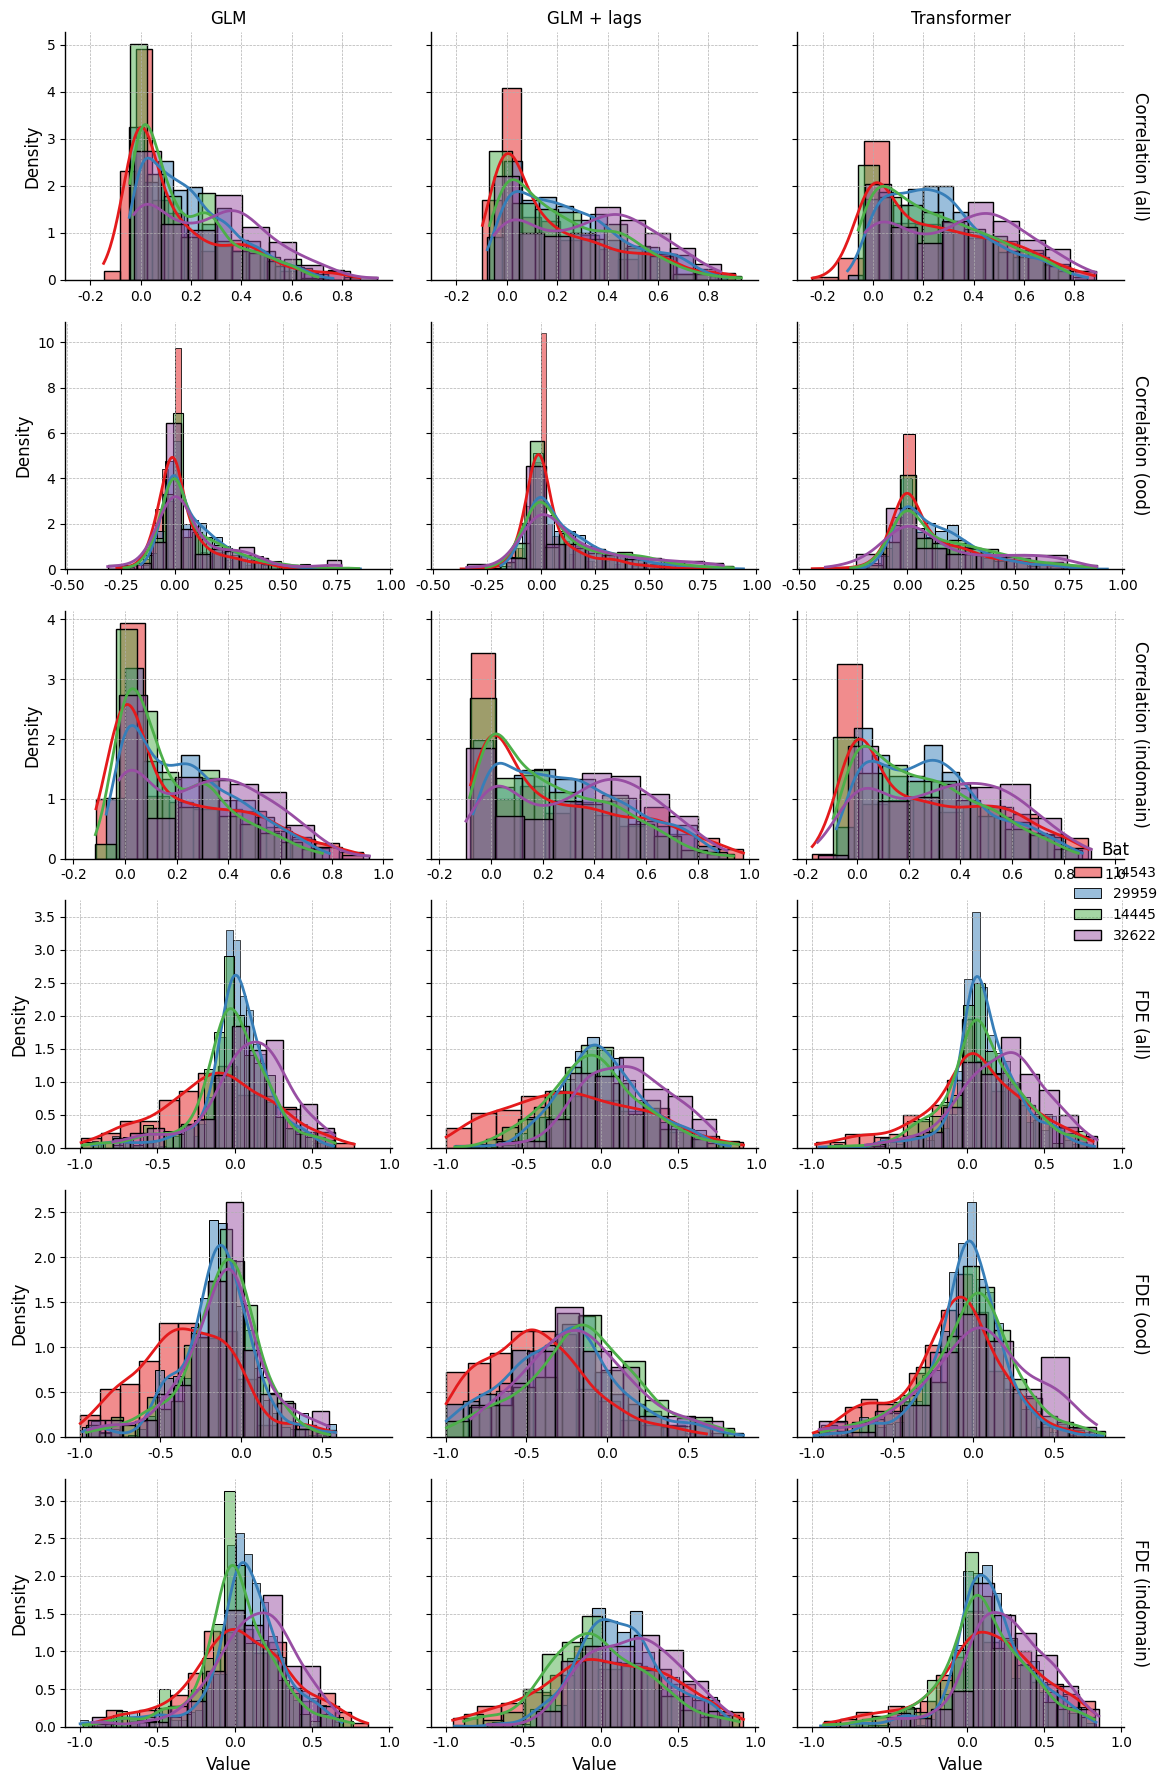

In [240]:
# Plot all sessions: col=model, row=metric+subset, hue=bat
df['row_label'] = df['metric'] + ' (' + df['subset'] + ')'

row_order = [
    'Correlation (all)', 'Correlation (ood)', 'Correlation (indomain)',
    'FDE (all)', 'FDE (ood)', 'FDE (indomain)'
]

col_order = ['GLM', 'GLM + lags', 'Transformer']

# Filter out FDE values <= -1
df_filtered = df[~((df['metric'] == 'FDE') & (df['value'] <= -1))]

g = sns.FacetGrid(
    df_filtered,
    col='model',
    row='row_label',
    hue='bat',
    col_order=col_order,
    row_order=row_order,
    height=3,
    aspect=1.2,
    palette='Set1',
    sharex='row',
    sharey='row',
    margin_titles=True
)

g.map(sns.histplot, 'value', kde=True, alpha=0.5, stat='density', common_norm=False)
g.set_axis_labels('Value', 'Density')
g.set_titles(col_template='{col_name}', row_template='{row_name}')
g.add_legend(title='Bat')
plt.tight_layout()
plt.show()

Wilcoxon signed-rank tests (H1: second model > first model)

==================== Subset: all ====================
--- Correlation ---
  GLM vs GLM + lags: n=1767, median diff=0.0326, p=1.95e-82 ***
  GLM vs Transformer: n=1767, median diff=0.0635, p=2.38e-134 ***
  GLM + lags vs Transformer: n=1767, median diff=0.0093, p=4.04e-14 ***
--- FDE ---
  GLM vs GLM + lags: n=1481, median diff=-0.0068, p=8.98e-01 
  GLM vs Transformer: n=1489, median diff=0.1095, p=9.72e-151 ***
  GLM + lags vs Transformer: n=1581, median diff=0.1150, p=9.39e-107 ***

==================== Subset: ood ====================
--- Correlation ---
  GLM vs GLM + lags: n=1767, median diff=0.0000, p=8.44e-17 ***
  GLM vs Transformer: n=1767, median diff=0.0198, p=4.81e-53 ***
  GLM + lags vs Transformer: n=1767, median diff=0.0000, p=6.10e-19 ***
--- FDE ---
  GLM vs GLM + lags: n=1157, median diff=-0.0966, p=1.00e+00 
  GLM vs Transformer: n=1252, median diff=0.1330, p=7.46e-67 ***
  GLM + lags vs Transformer: n=1224

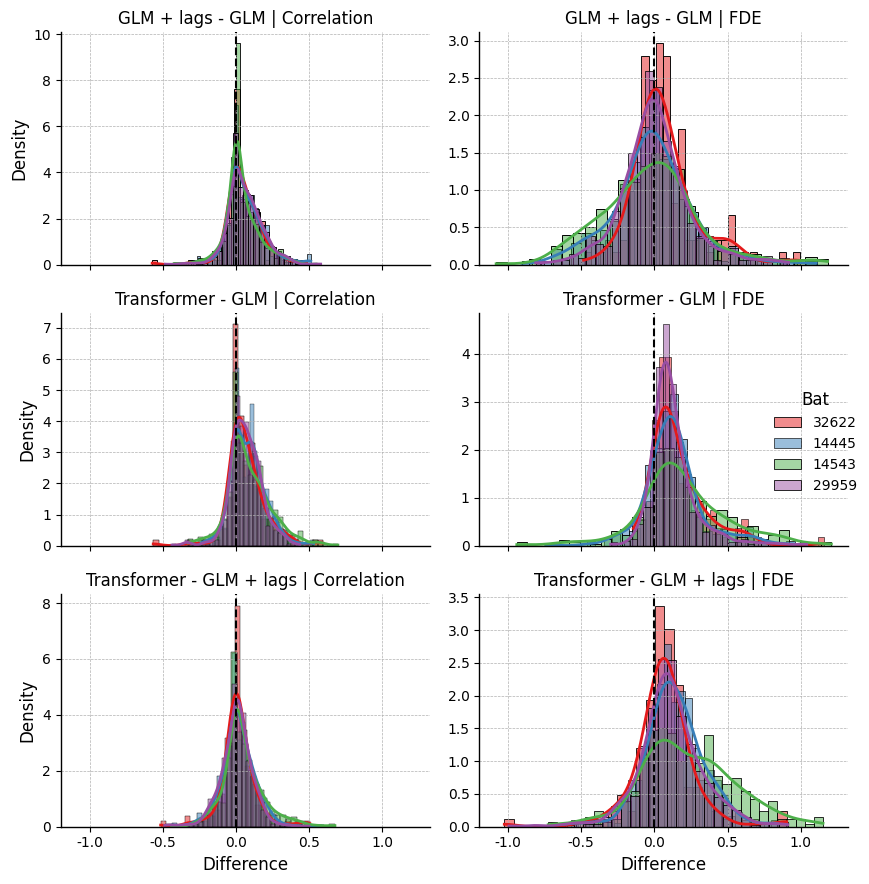

In [ ]:
# Wilcoxon signed-rank tests: pairwise model comparisons (per subset)
def wilcoxon_test(scores_a, scores_b, name):
    """Run Wilcoxon signed-rank test and print results."""
    mask = ~(np.isnan(scores_a) | np.isnan(scores_b))
    a, b = scores_a[mask], scores_b[mask]
    if len(a) < 10:
        print(f"{name}: n={len(a)} (too few samples)")
        return None
    stat, p = wilcoxon(a, b, alternative='less')
    median_diff = np.median(b - a)
    print(f"{name}: n={len(a)}, median diff={median_diff:.4f}, p={p:.2e} "
          f"{'***' if p<0.001 else '**' if p<0.01 else '*' if p<0.05 else ''}")
    return {'name': name, 'n': len(a), 'median_diff': median_diff, 'p': p}

model_pairs = [
    ('GLM', 'GLM + lags'),
    ('GLM', 'Transformer'),
    ('GLM + lags', 'Transformer'),
]

print("Wilcoxon signed-rank tests (H1: second model > first model)")
print("=" * 60)

stats_results = []
for subset in ['all', 'ood', 'indomain']:
    print(f"\n{'='*20} Subset: {subset} {'='*20}")
    df_subset = df_filtered[df_filtered['subset'] == subset]

    for metric in ['Correlation', 'FDE']:
        df_metric = df_subset[df_subset['metric'] == metric]
        df_pivot = df_metric.pivot_table(
            index=['session', 'bat', 'date', 'unit'], columns='model', values='value'
        ).reset_index()

        print(f"--- {metric} ---")
        for m_a, m_b in model_pairs:
            result = wilcoxon_test(
                df_pivot[m_a].values, df_pivot[m_b].values, f"  {m_a} vs {m_b}"
            )
            if result:
                stats_results.append({
                    **result, 'metric': metric, 'subset': subset,
                    'comparison': f'{m_a} vs {m_b}'
                })

df_stats = pd.DataFrame(stats_results)
print("\nSummary:")
print(df_stats[['metric', 'subset', 'comparison', 'n', 'median_diff', 'p']].to_string(index=False))

# Histogram of pairwise differences (for 'all' subset)
df_all = df_filtered[df_filtered['subset'] == 'all']

diff_rows = []
for metric in ['Correlation', 'FDE']:
    df_metric = df_all[df_all['metric'] == metric]
    df_pivot = df_metric.pivot_table(
        index=['session', 'bat', 'date', 'unit'], columns='model', values='value'
    ).reset_index()
    for m_a, m_b in model_pairs:
        d = df_pivot[m_b] - df_pivot[m_a]
        for val, bat in zip(d, df_pivot['bat']):
            diff_rows.append({'metric': metric, 'comparison': f'{m_b} - {m_a}', 'diff': val, 'bat': bat})

df_diff = pd.DataFrame(diff_rows)

g = sns.FacetGrid(
    df_diff, col='metric', row='comparison', hue='bat',
    height=3, aspect=1.3, palette='Set1', sharey=False
)
g.map(sns.histplot, 'diff', kde=True, alpha=0.5, stat='density', common_norm=False, bins=30)
for ax in g.axes.flat:
    ax.axvline(0, color='black', linestyle='--', lw=1.5)
g.set_axis_labels('Difference', 'Density')
g.set_titles(col_template='{col_name}', row_template='{row_name}')
g.add_legend(title='Bat')
plt.tight_layout()
plt.show()